# Boston 311 staffing plan and intake assistant

DADS 5250 hackathon: [Staffing Boston's 311 City Service Teams](https://www.ai2lab.ai/courses/DADS5250/hackathon/#p2)

This notebook plans 2025 field crews for four City of Boston 311 departments and builds an AI assistant that routes a resident's message to the right request type and department queue. The assistant sends requests to department queues, and the staffing plan decides how many crews work those queues.

| Section | Brief deliverable |
| --- | --- |
| Data ingestion | Shared data for every section |
| Demand forecast | 1. Demand forecast |
| Staffing model | 3. Dynamic staffing model |
| Sensitivity and other considerations | 5. Sensitivity analysis |
| Intake assistant and accuracy | 2. 311 intake assistant with GenAI |
| Intake assistant demo | 2. 311 intake assistant with GenAI |

The forecast feeds the staffing model, and the sensitivity tests reuse the staffing model, so those three run in a row. The intake assistant and its demo come last.

## Data ingestion

Load the 2023 and 2024 Boston 311 files into a local LanceDB database. The CSVs and the database share `./data`.

Four tables come out of this:

- `requests`: one row per in-scope request, cleaned, no vectors. Used for forecasting and staffing.
- `request_types`: one row per distinct request type, embedded by LanceDB. Used by the intake assistant to match a resident message to a type, department and queue.
- `type_aliases`: LLM-written resident phrasings for each type. Cached, so reruns do not call the LLM again.
- `intake_eval`: synthetic resident messages with the right answer, for measuring search accuracy.

Scope and gotchas come from the brief linked above.

Only the four departments in scope are kept: Public Works (PWDx), Transportation (BTDT), Parks (PARK) and Inspectional Services (ISD).

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import html
import math
from pathlib import Path

import lancedb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lancedb.index import FTS
from lancedb.pydantic import LanceModel, Vector

from core.llm import MODEL, parse
from core.models import AliasBatch, EvalBatch
from db.request_types import DATA, embedder

BASE = "https://data.boston.gov/dataset/8048697b-ad64-4bfc-b090-ee00169f2323/resource"
FILES = {
    "lagan_311_open_data_2023_rvsd3.csv": f"{BASE}/e6013a93-1321-4f2a-bf91-8d8a02f1e62f/download/lagan_311_open_data_2023_rvsd3.csv",
    "lagan_311_open_data_2024_rvsd3.csv": f"{BASE}/dff4d804-5031-443a-8409-8344efd0e5c8/download/lagan_311_open_data_2024_rvsd3.csv",
}
DEPARTMENTS = {
    "PWDx": "Public Works",
    "BTDT": "Transportation",
    "PARK": "Parks and Recreation",
    "ISD": "Inspectional Services",
}
OUTPUT_DIR = DATA.parent / "outputs"

DATA.mkdir(exist_ok=True)
db = lancedb.connect(DATA / "lancedb")


### Download

Files are cached in `./data`. A file that already exists is not fetched again. Each is about 180 MB.

In [4]:
import urllib.request
for name, url in FILES.items():
    path = DATA / name
    if not path.exists():
        tmp = path.with_suffix(".part")
        urllib.request.urlretrieve(url, tmp)
        tmp.rename(path)
    print(f"{name}: {path.stat().st_size / 1e6:.0f} MB")


lagan_311_open_data_2023_rvsd3.csv: 184 MB
lagan_311_open_data_2024_rvsd3.csv: 182 MB


### Load and clean

Gotchas handled here:

- Keep only the four departments.
- Text has HTML codes like `&amp;`, so decode them. Underscores in type names (`Mattress_Pickup`) become spaces.
- About 16% of requests have no `sla_target_dt` overall. In scope it is mostly Public Works. The nulls stay null and `has_sla` flags them.
- Some target dates are very long (Parks uses 365 days), so `sla_days` is kept for filtering later.
- 42% of 2024 requests are `Employee Generated`, so `is_employee` is kept for the resident vs employee split.
- Timestamps are Boston local time. They are stored without a timezone.
- `open_month` is added so monthly counts are one group-by away.

In [5]:
COLUMNS = [
    "case_enquiry_id", "open_dt", "sla_target_dt", "closed_dt", "on_time", "case_status",
    "case_title", "subject", "reason", "type", "queue", "department", "neighborhood", "source",
]
TEXT = ["case_title", "subject", "reason", "type", "queue", "neighborhood"]
DATES = ["open_dt", "sla_target_dt", "closed_dt"]


def clean_text(s: pd.Series) -> pd.Series:
    return s.map(lambda v: html.unescape(v) if isinstance(v, str) else v).str.replace("_", " ").str.strip()


def load(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, usecols=COLUMNS, dtype=str)
    df = df[df.department.isin(DEPARTMENTS)].copy()
    df[DATES] = df[DATES].apply(pd.to_datetime, format="ISO8601")
    df[TEXT] = df[TEXT].apply(clean_text)
    df["case_enquiry_id"] = df.case_enquiry_id.astype("int64")
    df["open_month"] = df.open_dt.dt.to_period("M").dt.to_timestamp()
    df["has_sla"] = df.sla_target_dt.notna()
    df["sla_days"] = (df.sla_target_dt - df.open_dt).dt.total_seconds() / 86400
    df["days_to_close"] = (df.closed_dt - df.open_dt).dt.total_seconds() / 86400
    df["is_on_time"] = df.on_time.eq("ONTIME")
    df["is_employee"] = df.source.eq("Employee Generated")
    return df


requests = pd.concat([load(DATA / name) for name in FILES], ignore_index=True)
requests = requests.drop_duplicates("case_enquiry_id")
print(f"{len(requests):,} in-scope requests")
requests.groupby([requests.open_dt.dt.year.rename("year"), "department"]).size().unstack()


558,663 in-scope requests


department,BTDT,ISD,PARK,PWDx
year,,,,
2023,75314,18123,17541,171268
2024,81447,18624,18736,157610


The 2024 row counts match the hackathon brief: 157,610 / 81,447 / 18,736 / 18,624.

### Case titles

`case_title` has thousands of variants, but every row also has a `type` from the department. Check how concentrated the titles are, and whether they carry anything the type does not.

In [6]:
def mode(s: pd.Series) -> str:
    return s.value_counts().index[0]


titles = requests.groupby("case_title").size().sort_values(ascending=False)
print(f"{len(titles):,} distinct titles for {requests.type.nunique()} types")
print(f"top 50 titles cover {titles.iloc[:50].sum() / titles.sum():.0%} of rows; {(titles == 1).mean():.0%} of titles appear once")
requests.case_title[~requests.case_title.isin(titles.index[:300])].drop_duplicates().sample(8, random_state=1).tolist()


7,431 distinct titles for 163 types
top 50 titles cover 89% of rows; 66% of titles appear once


['SCH 10/22 Chronic Dampness/Mold',
 'SCH3/3Unsatisfactory Living Conditions',
 'Planting: Doherty Playground - BPRD',
 'Tree In Park: Billings Field; West Roxbury',
 'Street Light Knock Downs//NOTIFIED LIGHTING INSPECTOR',
 'SCH6/16Maintenance Complaint - Residential',
 'Street Light Outages//gas printed for 2nd shift//',
 'PRINTED  //  General Lighting Reques  //  N.M.']

Rare titles are a real title with noise around it: scheduling codes in front (`SCH5/12`), work order notes (`PRINTED : replace twin arm`), place names after a colon. Instead of writing rules to strip that, let embeddings absorb it.

Hold out 20% of rows. Embed the distinct training titles, then give each held-out title the type of its nearest neighbor. The vectors have unit length, so the nearest title is the one with the largest dot product. OpenRouter takes at most 2,048 texts per embedding call, so `embed` sends them in batches.

In [7]:
def embed(texts: list[str]) -> np.ndarray:
    return np.array([v for i in range(0, len(texts), 2048) for v in embedder.compute_source_embeddings(texts[i:i + 2048])])


shuffled = requests.sample(frac=1, random_state=0)
cut = int(len(shuffled) * 0.8)
train, test = shuffled.iloc[:cut], shuffled.iloc[cut:]
known = train.groupby("case_title").type.agg(mode)
distinct = test.case_title.unique()
nearest = dict(zip(distinct, known.iloc[(embed(distinct.tolist()) @ embed(known.index.tolist()).T).argmax(1)]))
print(f"{(test.case_title.map(nearest) == test.type).mean():.4f} of held-out rows get the right type from their nearest title")


0.9963 of held-out rows get the right type from their nearest title


The nearest title predicts the department's own type for about 99.6% of held-out rows, with no cleaning rules. The `type` column is already the clean grouping, so titles are only used below as examples when describing a type.

Titles are the city's wording, not the resident's, so resident phrasing is added separately.

### Write the requests table

The table is rebuilt on every run, so re-running the notebook is safe.

In [8]:
db.create_table("requests", requests, mode="overwrite")
db.open_table("requests").count_rows()


558663

### Check

The 2024 request counts should match the brief.

In [9]:
brief_2024 = {"PWDx": 157610, "BTDT": 81447, "PARK": 18736, "ISD": 18624}
counts = db.open_table("requests").to_pandas()
counts = counts[counts.open_dt.dt.year == 2024].department.value_counts().to_dict()
assert counts == brief_2024, counts
counts


{'PWDx': 157610, 'BTDT': 81447, 'PARK': 18736, 'ISD': 18624}

## Demand forecast

**Author:** Charlotte Sy

### Objective

Forecast monthly 311 service request demand for four Boston city departments
for 2025 using historical request data from 2023 and 2024.

Departments:
- PWDx - Public Works
- BTDT - Transportation
- PARK - Parks and Recreation
- ISD - Inspectional Services

### Methodology

The forecast uses monthly seasonal averages from 2023 and 2024,
adjusted by each department's year-over-year growth rate.

### Deliverables

1. Monthly request counts for 2023 and 2024.
2. Department-level growth rates.
3. Monthly demand forecasts for 2025.
4. Backtesting and average percentage error.
5. Forecast visualizations.

### Data loading and exploration

This section inspects the historical requests loaded above, the same rows as the LanceDB `requests` table.

The dataset is inspected to verify the total number of requests, available columns, departments, and date range before performing the demand forecasting analysis.

In [10]:
print("Total requests:", len(requests))

print("\nAvailable columns:")
print(requests.columns.tolist())

print("\nRequests by department:")
print(requests["department"].value_counts())

print("\nDate range:")
print("Earliest:", requests["open_dt"].min())
print("Latest:", requests["open_dt"].max())

# Preview the first five rows
display(requests.head())


Total requests: 558663

Available columns:
['case_enquiry_id', 'open_dt', 'sla_target_dt', 'closed_dt', 'on_time', 'case_status', 'case_title', 'subject', 'reason', 'type', 'queue', 'department', 'neighborhood', 'source', 'open_month', 'has_sla', 'sla_days', 'days_to_close', 'is_on_time', 'is_employee']

Requests by department:
department
PWDx    328878
BTDT    156761
ISD      36747
PARK     36277
Name: count, dtype: int64

Date range:
Earliest: 2023-01-01 00:11:22.940000
Latest: 2024-12-31 23:47:03.657000


,case_enquiry_id,open_dt,sla_target_dt,closed_dt,on_time,case_status,case_title,subject,reason,type,queue,department,neighborhood,source,open_month,has_sla,sla_days,days_to_close,is_on_time,is_employee
0,101004616857,2023-01-02 15:50:52.307,2023-01-04 08:30:00.000,2023-01-03 09:41:31.773,ONTIME,Closed,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,Parking Enforcement,BTDT Parking Enforcement,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Employee Generated,2023-01-01,True,1.693839,0.743512,True,True
1,101004617727,2023-01-03 11:37:13.827,2023-01-04 11:37:14.000,2023-01-03 12:14:52.223,ONTIME,Closed,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,Parking Enforcement,BTDT Parking Enforcement,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Employee Generated,2023-01-01,True,1.000002,0.026139,True,True
2,101004620394,2023-01-05 09:51:54.313,2023-01-06 09:51:55.610,2023-01-05 15:11:48.023,ONTIME,Closed,Traffic Signal Inspection,Transportation - Traffic Division,Signs & Signals,Traffic Signal Inspection,BTDT Traffic Signal Repair,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Citizens Connect App,2023-01-01,True,1.000015,0.222149,True,False
3,101004621762,2023-01-06 11:20:53.710,2023-01-09 11:20:55.000,2023-01-07 06:30:08.457,ONTIME,Closed,Empty Litter Basket,Public Works Department,Highway Maintenance,Empty Litter Basket,PWDx District 10A: Roxbury,PWDx,Fenway / Kenmore / Audubon Circle / Longwood,Citizens Connect App,2023-01-01,True,3.000015,0.798087,True,False
4,101004622259,2023-01-06 15:57:07.403,2023-01-09 15:57:08.000,2023-01-06 17:48:32.340,ONTIME,Closed,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,Parking Enforcement,BTDT Parking Enforcement,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Citizens Connect App,2023-01-01,True,3.000007,0.077372,True,False


### Monthly request counts (2023-2024)

This section calculates the total number of Boston 311 service requests submitted each month for each department.

The monthly counts will be used to calculate department-level growth rates, generate the 2025 demand forecasts, and evaluate forecasting accuracy through backtesting.

In [11]:
# Create year and month columns from the request opening date
requests["year"] = requests["open_dt"].dt.year
requests["month"] = requests["open_dt"].dt.month

# Count requests by department, year, and month
monthly_counts = (
    requests.groupby(["department", "year", "month"])
    .size()
    .reset_index(name="request_count")
    .sort_values(["department", "year", "month"])
    .reset_index(drop=True)
)

# Verify the expected number of rows
print("Total monthly records:", len(monthly_counts))

# Verify the total number of requests
print("Total requests counted:", monthly_counts["request_count"].sum())

# Display monthly counts
display(monthly_counts)


Total monthly records: 96
Total requests counted: 558663


,department,year,month,request_count
0,BTDT,2023,1,5692
1,BTDT,2023,2,5316
2,BTDT,2023,3,6889
3,BTDT,2023,4,6143
4,BTDT,2023,5,6737
...,...,...,...,...
91,PWDx,2024,8,16398
92,PWDx,2024,9,15912
93,PWDx,2024,10,11639
94,PWDx,2024,11,10172


#### Monthly request count validation

The dataset contains 96 monthly records, calculated as:

$$
4 \text{ departments} \times 2 \text{ years} \times 12 \text{ months} = 96 \text{ records}
$$

Each department has 24 monthly observations covering January 2023 through December 2024.

The total monthly request counts should equal the original dataset total of 558,663 requests, confirming that all historical requests are accounted for in the aggregation.

### Department-level growth rates

This section calculates the annual growth rate for each department by comparing total service requests in 2023 and 2024.

The growth rate measures the percentage change in request volume between the two years and will be used to adjust the seasonal averages when forecasting demand for 2025.

The growth rate is calculated as:

$$
\text{Growth Rate} = \frac{\text{2024 Requests} - \text{2023 Requests}}{\text{2023 Requests}}
$$

A positive growth rate indicates an increase in service requests, while a negative growth rate indicates a decrease.

In [12]:
# Calculate annual request totals for each department
annual_counts = (
    monthly_counts.groupby(["department", "year"])["request_count"]
    .sum()
    .unstack("year")
)

# Rename columns for clarity
annual_counts = annual_counts.rename(
    columns={2023: "requests_2023", 2024: "requests_2024"}
)

# Calculate growth rate from 2023 to 2024
annual_counts["growth_rate"] = (
    (annual_counts["requests_2024"] - annual_counts["requests_2023"])
    / annual_counts["requests_2023"]
)

# Convert growth rate to a percentage for easier interpretation
annual_counts["growth_rate_pct"] = (
    annual_counts["growth_rate"] * 100
)

# Display results
print("Department-Level Annual Growth Rates (2023-2024):")

display(annual_counts.round(2))


Department-Level Annual Growth Rates (2023-2024):


year,requests_2023,requests_2024,growth_rate,growth_rate_pct
department,,,,
BTDT,75314,81447,0.08,8.14
ISD,18123,18624,0.03,2.76
PARK,17541,18736,0.07,6.81
PWDx,171268,157610,-0.08,-7.97


In [13]:
# Calculate total requests across all departments for each year
total_2023 = annual_counts["requests_2023"].sum()
total_2024 = annual_counts["requests_2024"].sum()

# Calculate overall growth rate
overall_growth_rate = (
    (total_2024 - total_2023) / total_2023
) * 100

# Display totals and overall growth rate
print("\nOverall Request Totals:")
print(f"2023 Total Requests: {total_2023:,}")
print(f"2024 Total Requests: {total_2024:,}")
print(f"Combined Requests: {total_2023 + total_2024:,}")
print(f"Overall Growth Rate: {overall_growth_rate:.2f}%")



Overall Request Totals:
2023 Total Requests: 282,246
2024 Total Requests: 276,417
Combined Requests: 558,663
Overall Growth Rate: -2.07%


#### Department-level growth rate analysis

The annual growth rates were calculated by comparing total service requests in 2023 and 2024 for each department.

Three departments experienced an increase in request volume:

- **BTDT:** 8.14% increase
- **ISD:** 2.76% increase
- **PARK:** 6.81% increase

**PWDx** experienced a 7.97% decrease in request volume.

Overall, total requests decreased from 282,246 in 2023 to 276,417 in 2024, representing an approximately 2.07% decline.

These department-level growth rates will be used as adjustment factors when generating the 2025 monthly demand forecasts.

### Monthly demand forecasts for 2025

This section generates monthly service request forecasts for 2025 using historical request counts from 2023 and 2024.

The forecasting method combines two components:

1. **Seasonal Average:** The average number of requests received during the same month in 2023 and 2024.
2. **Department-Level Growth Factor:** The annual growth rate calculated for each department in the previous section.

The seasonal average is calculated as:

$$
\text{Seasonal Average} = \frac{\text{2023 Monthly Requests} + \text{2024 Monthly Requests}}{2}
$$

The 2025 forecast is then calculated as:

$$
\text{2025 Forecast} = \text{Seasonal Average} \times (1 + \text{Department Growth Rate})
$$

This method accounts for historical monthly demand patterns while adjusting for changes in annual request volume.

The resulting forecast will contain 48 rows:

$$
4 \text{ departments} \times 12 \text{ months} = 48 \text{ forecasts}
$$

In [14]:
# Reshape monthly counts to compare 2023 and 2024 side by side
monthly_comparison = (
    monthly_counts
    .pivot(
        index=["department", "month"],
        columns="year",
        values="request_count"
    )
    .reset_index()
)

# Rename columns for clarity
monthly_comparison = monthly_comparison.rename(
    columns={
        2023: "requests_2023",
        2024: "requests_2024"
    }
)

# Calculate seasonal average for each department and month
monthly_comparison["seasonal_average"] = (
    monthly_comparison["requests_2023"]
    + monthly_comparison["requests_2024"]
) / 2

# Add department-level growth rates
monthly_comparison = monthly_comparison.merge(
    annual_counts[["growth_rate"]],
    left_on="department",
    right_index=True,
    how="left",
    validate="many_to_one"
)

# Calculate 2025 monthly demand forecasts
monthly_comparison["forecast_2025"] = (
    monthly_comparison["seasonal_average"]
    * (1 + monthly_comparison["growth_rate"])
)

# Round forecasts to whole requests
monthly_comparison["forecast_2025"] = (
    monthly_comparison["forecast_2025"]
    .round()
    .astype(int)
)

# Create the final forecast table
forecast_2025 = monthly_comparison[
    [
        "department",
        "month",
        "requests_2023",
        "requests_2024",
        "seasonal_average",
        "growth_rate",
        "forecast_2025"
    ]
].copy()

# Sort by department and month
forecast_2025 = forecast_2025.sort_values(
    ["department", "month"]
).reset_index(drop=True)

# Verify forecast results
print("Total forecast rows:", len(forecast_2025))
print("Departments:", forecast_2025["department"].nunique())
print("Months per department:")
print(forecast_2025.groupby("department")["month"].nunique())

# Verify that no forecast values are missing
assert len(forecast_2025) == 48, "Expected 48 forecast rows."
assert forecast_2025["forecast_2025"].notna().all(), (
    "Missing forecast values detected."
)

# Display forecast table
display(forecast_2025)


Total forecast rows: 48
Departments: 4
Months per department:
department
BTDT    12
ISD     12
PARK    12
PWDx    12
Name: month, dtype: int64


year,department,month,requests_2023,requests_2024,seasonal_average,growth_rate,forecast_2025
0,BTDT,1,5692,5620,5656.0,0.081432,6117
1,BTDT,2,5316,5954,5635.0,0.081432,6094
2,BTDT,3,6889,7209,7049.0,0.081432,7623
3,BTDT,4,6143,7008,6575.5,0.081432,7111
4,BTDT,5,6737,7511,7124.0,0.081432,7704
5,BTDT,6,6682,7176,6929.0,0.081432,7493
6,BTDT,7,5517,6678,6097.5,0.081432,6594
7,BTDT,8,6473,6719,6596.0,0.081432,7133
8,BTDT,9,7190,7633,7411.5,0.081432,8015
9,BTDT,10,7018,7675,7346.5,0.081432,7945


#### 2025 monthly demand forecast validation

The forecasting process generated 48 monthly demand predictions for 2025, covering all four departments (BTDT, ISD, PARK, and PWDx).

Each department contains 12 monthly forecasts, representing January through December 2025.

The forecasts were calculated using the average monthly request volume from 2023 and 2024, adjusted by each department's annual growth rate.

For example, the January 2025 forecast for BTDT was calculated as follows:

**January 2023 Requests:** 5,692

**January 2024 Requests:** 5,620

**BTDT Annual Growth Rate:** 8.14%

Calculate the seasonal average:

$$
\frac{5692+5620}{2}=5656
$$

Apply the department growth factor:

$$
5656\times(1+0.081432)\approx6117
$$

The predicted number of BTDT service requests for January 2025 is approximately **6,117 requests**.

This approach preserves historical monthly demand patterns while accounting for department-level changes in annual request volume.

The resulting forecasts will be evaluated through backtesting against actual 2024 request counts in the next section.

### Backtesting against 2024

This section checks how accurate our forecasting approach is by comparing predicted requests for 2024 with the actual number of requests received.

Since we only have data from 2023 and 2024, we'll use the monthly request counts from 2023 to predict the same months in 2024.

For example, January 2023 requests will be used to predict January 2024 requests.

The prediction is calculated as:

$$
\text{Predicted 2024 Requests} = \text{Actual 2023 Requests}
$$

To measure accuracy, we'll calculate the percentage difference between the predicted and actual requests:

$$
\text{Percentage Error} = \frac{|\text{Actual} - \text{Predicted}|}{\text{Actual}} \times 100
$$

We'll then calculate the average percentage error across all 12 months for each department.

A lower average percentage error means the predictions were closer to the actual request counts.

Note: This backtest uses 2023 monthly requests as a baseline rather than the growth-adjusted method used for the 2025 forecasts, since we don't have data from before 2023 to calculate an earlier growth rate.

In [15]:
# Create backtesting dataset
backtest_2024 = monthly_comparison[
    ["department", "month", "requests_2023", "requests_2024"]
].copy()

# Use 2023 monthly requests to predict 2024
backtest_2024["predicted_2024"] = (
    backtest_2024["requests_2023"]
)

# Calculate absolute percentage error for each month
backtest_2024["absolute_percentage_error"] = (
    abs(
        backtest_2024["requests_2024"]
        - backtest_2024["predicted_2024"]
    )
    / backtest_2024["requests_2024"]
) * 100

# Calculate average percentage error for each department
backtest_summary = (
    backtest_2024
    .groupby("department")["absolute_percentage_error"]
    .mean()
    .reset_index(name="MAPE_percent")
)

# Validate backtesting results
assert len(backtest_2024) == 48, "Expected 48 backtesting records."
assert (backtest_2024["requests_2024"] > 0).all(), (
    "MAPE requires nonzero actual request counts."
)

print("Backtesting Results: Monthly Predictions vs Actual 2024")
display(backtest_2024.round(2))

print("\nAverage Percentage Error by Department:")
display(backtest_summary.round(2))


Backtesting Results: Monthly Predictions vs Actual 2024


year,department,month,requests_2023,requests_2024,predicted_2024,absolute_percentage_error
0,BTDT,1,5692,5620,5692,1.28
1,BTDT,2,5316,5954,5316,10.72
2,BTDT,3,6889,7209,6889,4.44
3,BTDT,4,6143,7008,6143,12.34
4,BTDT,5,6737,7511,6737,10.30
5,BTDT,6,6682,7176,6682,6.88
6,BTDT,7,5517,6678,5517,17.39
7,BTDT,8,6473,6719,6473,3.66
8,BTDT,9,7190,7633,7190,5.80
9,BTDT,10,7018,7675,7018,8.56



Average Percentage Error by Department:


,department,MAPE_percent
0,BTDT,7.64
1,ISD,13.33
2,PARK,17.73
3,PWDx,13.59


#### Backtesting results and analysis

The backtesting results compare predicted monthly requests for 2024 against the actual 2024 request counts.

The Mean Absolute Percentage Error (MAPE) for each department was:

- **BTDT:** 7.64%
- **ISD:** 13.33%
- **PARK:** 17.73%
- **PWDx:** 13.59%

BTDT had the lowest average forecasting error at 7.64%, meaning its monthly request counts were relatively close to the previous year's values.

PARK had the highest average forecasting error at 17.73%, indicating greater differences between its 2023 and 2024 monthly request counts.

ISD and PWDx had similar average errors of approximately 13%.

Overall, the results show that forecasting accuracy varies by department.

**Limitation:** Because only 2023 and 2024 data are available, this backtest uses 2023 monthly counts to predict 2024. Therefore, these results evaluate a simple seasonal baseline rather than the growth-adjusted forecasting method used for 2025.

### Monthly demand forecast charts

This section compares historical monthly request counts from 2023 and 2024 with the predicted demand for 2025.

A separate line chart is created for each department (BTDT, ISD, PARK, and PWDx).

Each chart displays:
- **2023 Actual:** Monthly service requests received in 2023.
- **2024 Actual:** Monthly service requests received in 2024.
- **2025 Forecast:** Predicted monthly requests based on seasonal averages and department growth rates.

These visualizations help identify seasonal patterns and differences between historical and forecasted demand.

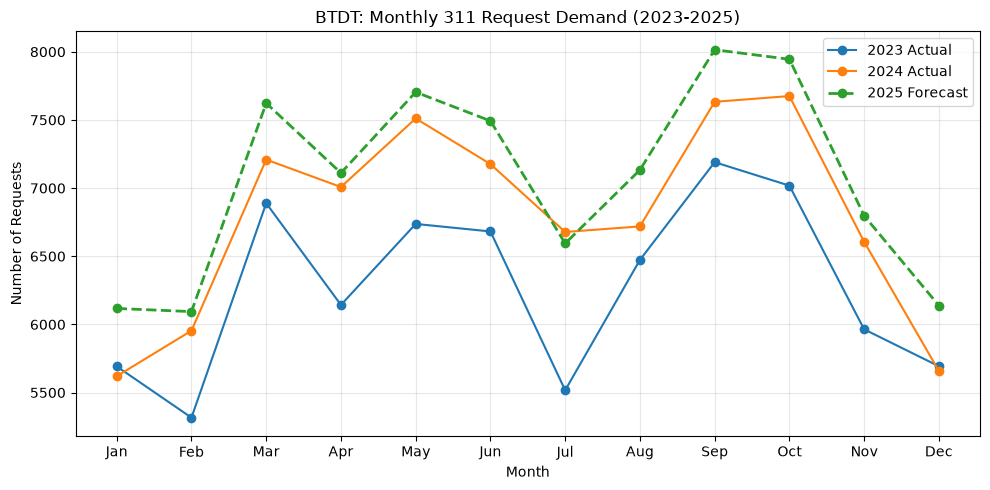

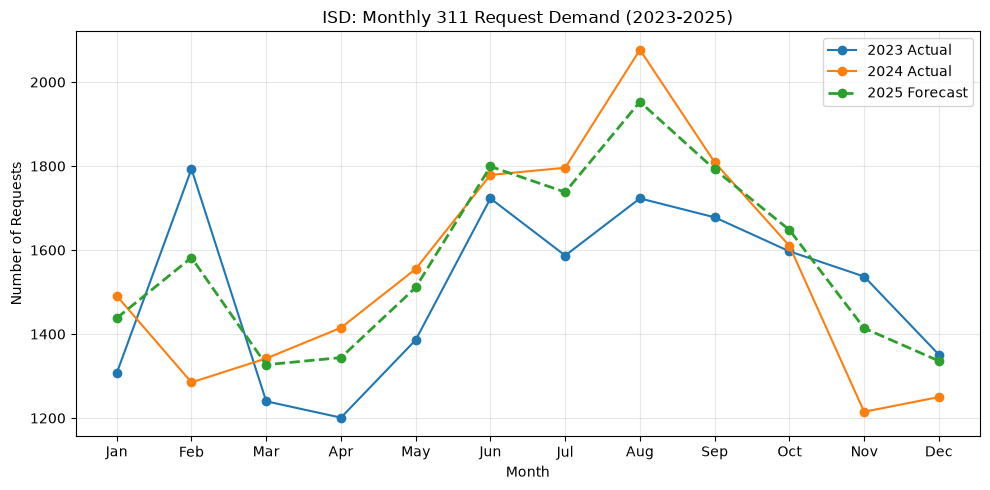

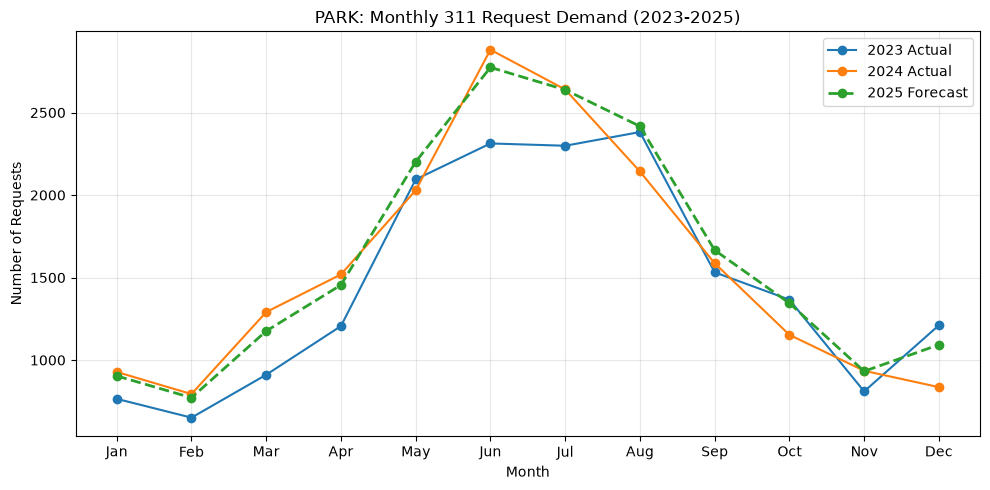

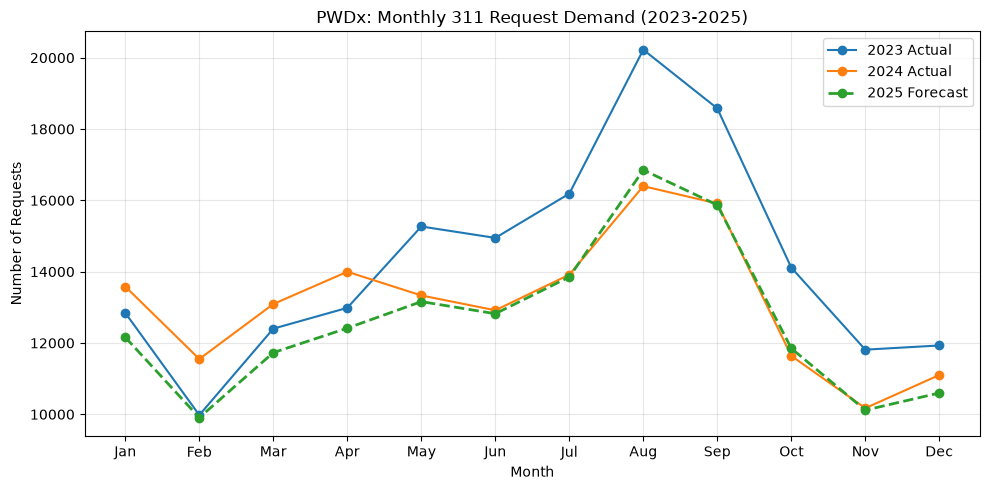

In [16]:
# Month labels for the x-axis
month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

# Create a separate line chart for each department
departments = ["BTDT", "ISD", "PARK", "PWDx"]

for dept in departments:

    # Filter data for the current department
    dept_data = forecast_2025[
        forecast_2025["department"] == dept
    ].sort_values("month")

    # Create chart
    plt.figure(figsize=(10, 5))

    # Plot actual 2023 requests
    plt.plot(
        dept_data["month"],
        dept_data["requests_2023"],
        marker="o",
        label="2023 Actual"
    )

    # Plot actual 2024 requests
    plt.plot(
        dept_data["month"],
        dept_data["requests_2024"],
        marker="o",
        label="2024 Actual"
    )

    # Plot forecasted 2025 requests
    plt.plot(
        dept_data["month"],
        dept_data["forecast_2025"],
        marker="o",
        linestyle="--",
        linewidth=2,
        label="2025 Forecast"
    )

    # Chart formatting
    plt.title(f"{dept}: Monthly 311 Request Demand (2023-2025)")
    plt.xlabel("Month")
    plt.ylabel("Number of Requests")

    plt.xticks(range(1, 13), month_labels)

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


#### Results and analysis

The four charts compare the actual monthly requests from 2023 and 2024 with the predicted requests for 2025.

**Key Observations:**

- **BTDT:** Requests increased from 2023 to 2024. The 2025 forecast shows higher demand around September and October.
- **ISD:** Requests change throughout the year, with higher demand during the summer months.
- **PARK:** Requests are generally higher during the spring and summer and lower toward the end of the year.
- **PWDx:** Requests decreased from 2023 to 2024. The 2025 forecast reflects this decrease.

**Overall Results:**

The charts show that each department has different monthly demand patterns. BTDT, ISD, and PARK had an overall increase in requests, while PWDx had a decrease.

The 2025 forecasts use the monthly averages from 2023 and 2024, along with each department's growth rate, to estimate future requests.

### Export and validate final results

This section saves the final 2025 demand forecast as a CSV file so it can be used by other parts of the project.

The final forecast includes:
- Department
- Month
- Predicted number of requests for 2025

Before saving, the data is checked to make sure all four departments have 12 months of predictions, for a total of 48 rows.

In [17]:
# Select the columns needed for the final forecast
final_forecast = forecast_2025[
    ["department", "month", "forecast_2025"]
].copy()

# Sort by department and month
final_forecast = final_forecast.sort_values(
    ["department", "month"]
).reset_index(drop=True)

# Check that the forecast has 48 rows
assert len(final_forecast) == 48, "Expected 48 forecast rows."

# Check that there are 4 departments
assert final_forecast["department"].nunique() == 4, \
    "Expected 4 departments."

# Check that each department has 12 months
assert (
    final_forecast.groupby("department")["month"].nunique() == 12
).all(), "Each department must have 12 months."

# Check for missing or negative forecast values
assert final_forecast["forecast_2025"].notna().all(), \
    "Forecast contains missing values."

assert (final_forecast["forecast_2025"] >= 0).all(), \
    "Forecast contains negative values."

# Create an outputs folder in the project
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the forecast as a CSV file
forecast_file = OUTPUT_DIR / "demand_forecast_2025.csv"

final_forecast.to_csv(forecast_file, index=False)

# Display the results
print("Forecast validation passed!")
print(f"Total forecast rows: {len(final_forecast)}")
print(f"Departments: {final_forecast['department'].nunique()}")
print(f"CSV saved to: {forecast_file}")

display(final_forecast)


Forecast validation passed!
Total forecast rows: 48
Departments: 4
CSV saved to: D:\Projects\School\Northeastern\DADS_5250_AI_in_Practice\hackathon\dads5250-311-intake-assistant\outputs\demand_forecast_2025.csv


year,department,month,forecast_2025
0,BTDT,1,6117
1,BTDT,2,6094
2,BTDT,3,7623
3,BTDT,4,7111
4,BTDT,5,7704
5,BTDT,6,7493
6,BTDT,7,6594
7,BTDT,8,7133
8,BTDT,9,8015
9,BTDT,10,7945


In [18]:
# Save the backtesting summary as a CSV file
backtest_file = OUTPUT_DIR / "demand_backtest_2024.csv"

backtest_summary.to_csv(backtest_file, index=False)

# Confirm the file was saved
print("Backtesting results saved!")
print(f"CSV saved to: {backtest_file}")

# Display the results
display(backtest_summary.round(2))


Backtesting results saved!
CSV saved to: D:\Projects\School\Northeastern\DADS_5250_AI_in_Practice\hackathon\dads5250-311-intake-assistant\outputs\demand_backtest_2024.csv


,department,MAPE_percent
0,BTDT,7.64
1,ISD,13.33
2,PARK,17.73
3,PWDx,13.59


## Staffing model

**Author:** Larry Tsao

### Objective

Decide how many field crews each of the four departments needs in each month of 2025, including when to hire and release crews, and compare the cost and service level of different staffing plans. The sensitivity section after this one tests how the recommended plan holds up when demand changes, and looks at response times by neighborhood and by who reports the request.

Departments:
- BTDT - Transportation
- ISD - Inspectional Services
- PARK - Parks and Recreation
- PWDx - Public Works

### Methodology

The 2025 demand forecast is turned into the number of crews each month needs. A staffing plan then hires, releases, or adds seasonal crews following the rules in the hackathon brief. A month-by-month backlog simulation measures each plan's cost and how many requests get closed in the month they come in.

### Deliverables

1. Crews needed per department per month.
2. A staffing plan with hires, releases, and Parks seasonal crews.
3. A cost and service comparison against holding January 2025 crew levels.
4. A recommended plan with a crew table by month.
5. A check of the simulation against real 2024 performance.
6. Visualizations of demand and crew capacity.
7. CSV exports of the crew plan and plan comparison.

### Forecast input

The staffing model starts from the 2025 demand forecast (`forecast_2025`). The 2023 and 2024 requests loaded above are used again to check the simulation against 2024.

In [19]:
forecast_2025.pivot(index="month", columns="department", values="forecast_2025")


department,BTDT,ISD,PARK,PWDx
month,,,,
1,6117,1438,904,12159
2,6094,1582,772,9906
3,7623,1327,1176,11730
4,7111,1344,1455,12416
5,7704,1511,2202,13160
6,7493,1799,2774,12821
7,6594,1738,2638,13851
8,7133,1953,2417,16851
9,8015,1792,1666,15870


#### Forecast check

The forecast has 48 rows (4 departments x 12 months). Total 2025 requests:

- **BTDT:** 84,764
- **ISD:** 18,882
- **PARK:** 19,374
- **PWDx:** 151,327

### Planning assumptions from the brief

This section stores the planning assumptions given in the hackathon brief. These numbers are assumed for the challenge, the same way a business case gives salaries.

A crew works 21 days a month, so:

Monthly capacity of one crew = requests it closes per day x 21

Other rules from the brief:
- A new crew needs **1 month** of hiring and training before it starts.
- Releasing a crew needs **1 month of notice** and costs **25%** of its annual cost.
- Parks may add **seasonal crews from April to October** at **1.3 times** the monthly cost, with no training delay and no release cost.
- Each overdue request costs **$20**. A request still open a month later costs an extra **$100**.

In [20]:
WORK_DAYS = 21
RELEASE_FEE = 0.25          # share of annual cost
SEASONAL_MULTIPLIER = 1.3   # Parks seasonal crews cost 30% more
OVERDUE_COST = 20           # first month a request is late
LATE_COST = 100             # extra cost when still open a month later

departments = {
    "BTDT": {"name": "Transportation", "daily_capacity": 15, "annual_cost": 110000, "starting_crews": 18},
    "ISD": {"name": "Inspectional Services", "daily_capacity": 4, "annual_cost": 140000, "starting_crews": 16},
    "PARK": {"name": "Parks and Recreation", "daily_capacity": 6, "annual_cost": 120000, "starting_crews": 10},
    "PWDx": {"name": "Public Works", "daily_capacity": 12, "annual_cost": 130000, "starting_crews": 50},
}

# Monthly capacity and monthly cost of one crew
for dept in departments:
    departments[dept]["monthly_capacity"] = departments[dept]["daily_capacity"] * WORK_DAYS
    departments[dept]["monthly_cost"] = departments[dept]["annual_cost"] / 12

display(pd.DataFrame(departments).T)


,name,daily_capacity,annual_cost,starting_crews,monthly_capacity,monthly_cost
BTDT,Transportation,15,110000,18,315,9166.666667
ISD,Inspectional Services,4,140000,16,84,11666.666667
PARK,Parks and Recreation,6,120000,10,126,10000.0
PWDx,Public Works,12,130000,50,252,10833.333333


### Crews needed each month

This section calculates how many crews each department needs to keep up with the forecast in each month:

Crews needed = forecast requests / monthly capacity of one crew, rounded up

It is rounded up, because a department cannot have part of a crew. The table also compares January's need with the starting crews from the brief.

In [21]:
def get_crews_needed(dept, dept_demand):
    needed = []
    for requests_in_month in dept_demand:
        needed.append(math.ceil(requests_in_month / departments[dept]["monthly_capacity"]))
    return needed


demand = {}
crews_needed = {}
for dept in departments:
    dept_forecast = forecast_2025[forecast_2025["department"] == dept].sort_values("month")
    demand[dept] = dept_forecast["forecast_2025"].tolist()
    crews_needed[dept] = get_crews_needed(dept, demand[dept])

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(pd.DataFrame(crews_needed, index=month_labels).T)

# Compare starting crews with the average month
for dept in departments:
    average_need = sum(demand[dept]) / 12
    starting_capacity = departments[dept]["starting_crews"] * departments[dept]["monthly_capacity"]
    print(f"{dept}: starting crews can close {starting_capacity / average_need:.0%} of an average 2025 month")


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
BTDT,20,20,25,23,25,24,21,23,26,26,22,20
ISD,18,19,16,16,18,22,21,24,22,20,17,16
PARK,8,7,10,12,18,23,21,20,14,11,8,9
PWDx,49,40,47,50,53,51,55,67,63,48,41,43


BTDT: starting crews can close 80% of an average 2025 month
ISD: starting crews can close 85% of an average 2025 month
PARK: starting crews can close 78% of an average 2025 month
PWDx: starting crews can close 100% of an average 2025 month


#### Crews needed analysis

Three departments start 2025 with fewer crews than an average month needs.

- **BTDT:** 80% of an average month. January needs 20 crews, but it only has 18.
- **ISD:** 85%. January needs 18 crews, but it only has 16.
- **PARK:** 78%. Parks actually has extra crews in winter (it needs 8 in January), but it needs 23 in June.
- **PWDx:** 100%, so it's fine on an average month. However, it needs 67 crews in August and only has 50.

Since new crews take a month to train, I have to hire ahead of the busy months.

### Staffing plan

This section builds a month-by-month staffing plan for one department. The rules are:

1. **January** uses the starting crews from the brief.
2. **Hiring:** a crew that starts working in a month was hired the month before and spends that month in training. For example, a crew that starts in February is hired and trained in January. The plan table shows each crew in the month it starts working.
3. **Releasing:** a crew that leaves in a month was given its one month of notice the month before, and it keeps working and getting paid during that notice month. The plan table shows each release in the month the crew is gone.
4. **Only idle crews are released.** A crew is kept while requests from earlier months are still waiting for it. Otherwise it is released only if it would sit idle long enough to pay for the release. The release fee equals 3 months of pay, and a crew that is needed again later also costs 1 month of training pay to rehire, so it has to be idle for **more than 4 months in a row** (more than 3 if it is not needed again within a year). The idle count looks past December into early 2026, assuming 2026 follows the same monthly pattern as the 2025 forecast. Without that, no crew could ever be released in the fall, because too few months are left in the year. When the plan has a crew ceiling, a crew above the ceiling is never used again under that plan, so it counts as idle for the whole year.
5. **Parks** covers April to October with seasonal crews instead of permanent hires.
6. An optional **crew ceiling** (`cap`) limits how many crews the plan may use. The crew ceiling search below uses it to avoid hiring for short peaks.

The baseline plan, **Hold January**, keeps the January crews all year.

Each function takes the department's monthly demand as an input, so the same functions can be rerun with higher or lower demand in the sensitivity section.

In [22]:
def is_parks_season(dept, month_index):
    # month_index runs from 0 (January) to 11 (December)
    month_number = month_index + 1
    return dept == "PARK" and 4 <= month_number <= 10


def idle_months(target, start, crews):
    # Count how many months in a row, starting at `start`, the department needs fewer than `crews` crews.
    # After December it keeps counting into 2026, assuming 2026 follows the same monthly pattern as 2025.
    count = 0
    for step in range(12):
        m = (start + step) % 12
        if target[m] >= crews:
            break
        count = count + 1
    return count


def make_plan(dept, dept_demand, cap=None):
    needed = get_crews_needed(dept, dept_demand)

    # Crews the plan aims for each month, limited by the ceiling if there is one
    target = []
    for n in needed:
        if cap is not None and n > cap:
            target.append(cap)
        else:
            target.append(n)

    # January is fixed at the starting crews
    permanent = [departments[dept]["starting_crews"]]
    hires = [0]
    releases = [0]

    # Requests still waiting at the end of January
    capacity = departments[dept]["monthly_capacity"]
    waiting = max(0, dept_demand[0] - permanent[0] * capacity)

    # February (index 1) to December (index 11)
    for m in range(1, 12):
        crews = permanent[-1]
        hired = 0
        released = 0

        # Hire up to the month's need (Parks uses seasonal crews in season instead)
        if target[m] > crews and not is_parks_season(dept, m):
            hired = target[m] - crews
            crews = target[m]

        # Crews needed to close this month's requests plus the ones still waiting
        needed_with_waiting = math.ceil((waiting + dept_demand[m]) / capacity)

        # Release only idle crews, and only if the idle stretch pays for the release
        while crews > max(target[m], needed_with_waiting):
            idle = idle_months(target, m, crews)
            if idle == 12:
                break_even = 3   # never needed again: release fee only
            else:
                break_even = 4   # needed again later: release fee + 1 month of training pay
            if idle <= break_even:
                break
            crews = crews - 1
            released = released + 1

        permanent.append(crews)
        hires.append(hired)
        releases.append(released)

        # Requests still waiting at the end of this month (Parks seasonal crews count in season)
        if is_parks_season(dept, m):
            working_crews = crews + max(0, target[m] - crews)
        else:
            working_crews = crews
        waiting = max(0, waiting + dept_demand[m] - working_crews * capacity)

    # Parks seasonal crews fill any gap from April to October
    seasonal = []
    for m in range(12):
        if is_parks_season(dept, m):
            seasonal.append(max(0, target[m] - permanent[m]))
        else:
            seasonal.append(0)

    return pd.DataFrame({
        "month": month_labels,
        "demand": dept_demand,
        "crews_needed": needed,
        "permanent": permanent,
        "hires": hires,
        "releases": releases,
        "seasonal": seasonal,
    })


def hold_january_plan(dept, dept_demand):
    starting = departments[dept]["starting_crews"]
    return pd.DataFrame({
        "month": month_labels,
        "demand": dept_demand,
        "crews_needed": get_crews_needed(dept, dept_demand),
        "permanent": [starting] * 12,
        "hires": [0] * 12,
        "releases": [0] * 12,
        "seasonal": [0] * 12,
    })


# Example: Transportation under the full-coverage rule
display(make_plan("BTDT", demand["BTDT"]))


,month,demand,crews_needed,permanent,hires,releases,seasonal
0,Jan,6117,20,18,0,0,0
1,Feb,6094,20,20,2,0,0
2,Mar,7623,25,25,5,0,0
3,Apr,7111,23,25,0,0,0
4,May,7704,25,25,0,0,0
5,Jun,7493,24,25,0,0,0
6,Jul,6594,21,25,0,0,0
7,Aug,7133,23,25,0,0,0
8,Sep,8015,26,26,1,0,0
9,Oct,7945,26,26,0,0,0


### Backlog and cost simulation

This section plays out a plan month by month. Each month:

1. Crews close requests up to their capacity, **oldest first**.
2. A new request still open at the end of its first month is **overdue** and costs **$20**.
3. A request still open at the end of the next month costs an extra **$100**. The brief charges this at 30 days past the request's target date; the team plan uses the month boundary instead.
4. A request is counted as **closed same month** if it is closed in the month it was opened. This is the model's stand-in for "on time" (the simulation check against 2024 explains how it compares with the city's real target dates).

**Training pay:** the brief does not say whether the month of hiring and training is paid. To me it makes more sense to have the training month paid, so every new permanent crew costs one extra month of pay for its training month. Parks seasonal crews have no training delay, so they have no training cost.

Total cost = crew pay + seasonal crew pay (at 1.3 times) + training pay + release fees + overdue costs

The 2025 simulation starts with no backlog, as the brief allows. Costs are the costs incurred during 2025, so the backlog still open in December is reported separately.

In [23]:
def simulate(dept, plan):
    info = departments[dept]
    plan = plan.reset_index(drop=True)  # rows numbered 0-11, even if the plan was filtered from a bigger table
    carried_once = 0    # requests left over from last month
    carried_twice = 0   # requests left over for two months or more
    closed_same_month = 0
    overdue_cost = 0

    for m in range(12):
        capacity = (plan["permanent"][m] + plan["seasonal"][m]) * info["monthly_capacity"]
        new_requests = plan["demand"][m]

        # Close the oldest requests first
        close_twice = min(carried_twice, capacity)
        capacity = capacity - close_twice
        close_once = min(carried_once, capacity)
        capacity = capacity - close_once
        close_new = min(new_requests, capacity)
        closed_same_month = closed_same_month + close_new

        # Whatever is left becomes next month's backlog
        new_left = new_requests - close_new
        once_left = carried_once - close_once
        twice_left = carried_twice - close_twice
        overdue_cost = overdue_cost + new_left * OVERDUE_COST + once_left * LATE_COST
        carried_twice = twice_left + once_left
        carried_once = new_left

    crew_cost = (plan["permanent"] * info["monthly_cost"]).sum()
    seasonal_cost = (plan["seasonal"] * info["monthly_cost"] * SEASONAL_MULTIPLIER).sum()
    training_cost = plan["hires"].sum() * info["monthly_cost"]
    release_cost = plan["releases"].sum() * info["annual_cost"] * RELEASE_FEE
    total_cost = crew_cost + seasonal_cost + training_cost + release_cost + overdue_cost

    return {
        "department": dept,
        "crew_cost": crew_cost + seasonal_cost,
        "training_cost": training_cost,
        "release_cost": release_cost,
        "overdue_cost": overdue_cost,
        "total_cost": total_cost,
        "same_month_rate": closed_same_month / plan["demand"].sum(),
        "backlog_in_december": carried_once + carried_twice,
        "requests": plan["demand"].sum(),
        "closed_same_month": closed_same_month,
    }


# Example: Transportation under the full-coverage rule
simulate("BTDT", make_plan("BTDT", demand["BTDT"]))


{'department': 'BTDT',
 'crew_cost': np.float64(2658333.333333333),
 'training_cost': np.float64(73333.33333333333),
 'release_cost': np.float64(27500.0),
 'overdue_cost': np.int64(13760),
 'total_cost': np.float64(2772926.6666666665),
 'same_month_rate': np.float64(0.9918833467037893),
 'backlog_in_december': np.int64(0),
 'requests': np.int64(84764),
 'closed_same_month': np.int64(84076)}

### Full coverage vs holding January

This section compares two plans for every department:

- **Hold January:** keep the January 2025 crews all year.
- **Full coverage:** the team plan's rule from the staffing plan section, with no crew ceiling.

In [24]:
results = []
for dept in departments:
    result = simulate(dept, hold_january_plan(dept, demand[dept]))
    result["plan"] = "Hold January"
    results.append(result)

    result = simulate(dept, make_plan(dept, demand[dept]))
    result["plan"] = "Full coverage"
    results.append(result)

comparison = pd.DataFrame(results)
display(comparison[["plan", "department", "total_cost", "same_month_rate", "backlog_in_december"]].round(3))


,plan,department,total_cost,same_month_rate,backlog_in_december
0,Hold January,BTDT,6598620.000,0.235,16724
1,Full coverage,BTDT,2772926.667,0.992,0
2,Hold January,ISD,2918920.000,0.368,2754
3,Full coverage,ISD,3071813.333,0.991,0
4,Hold January,PARK,2520380.000,0.274,5182
5,Full coverage,PARK,1837000.000,1.000,0
6,Hold January,PWDx,7272900.000,0.745,4316
7,Full coverage,PWDx,7680833.333,1.000,0


#### Full coverage vs hold January analysis

Full coverage closes over 99% of requests in the same month for every department. Holding January only closes between 23.5% (BTDT) and 74.5% (PWDx).

- **BTDT:** $6.60M down to $2.77M, since holding January lets the backlog keep growing.
- **PARK:** $2.52M down to $1.84M.
- **ISD:** $2.92M up to $3.07M.
- **PWDx:** $7.27M up to $7.68M.

Full coverage costs more for ISD and PWDx because it hires crews for short busy stretches and pays to train and release them. For example, it hires 12 Public Works crews for August and releases all of them by October. The next section looks for a plan that avoids this.

### Recommended crew ceiling

Full coverage hires for every peak, even one that lasts a single month. This section tries one crew ceiling at a time for each department, from its highest monthly need down to its lowest, and keeps:

- **Recommended:** the cheapest ceiling that still closes at least **95%** of requests in the same month. The 95% floor is our team's choice, not a number from the brief.
- **Cheapest ceiling tested:** the ceiling with the lowest total cost, whatever the service level.

This only tests one ceiling per department, so it is not a search over every possible month-by-month schedule.

In [25]:
MIN_SAME_MONTH_RATE = 0.95

recommended_cap = {}
cheapest_cap = {}
search_results = {}

for dept in departments:
    options = []
    needed = get_crews_needed(dept, demand[dept])
    highest_need = max(needed)
    lowest_need = min(needed)
    for cap in range(highest_need, lowest_need - 1, -1):
        result = simulate(dept, make_plan(dept, demand[dept], cap))
        options.append({"cap": cap, "total_cost": result["total_cost"], "same_month_rate": result["same_month_rate"]})
    options = pd.DataFrame(options)
    search_results[dept] = options

    # Cheapest ceiling of all
    by_cost = options.sort_values("total_cost")
    cheapest_cap[dept] = by_cost["cap"].iloc[0]

    # Cheapest ceiling that still meets the 95% floor (if none does, use no ceiling)
    good_enough = by_cost[by_cost["same_month_rate"] >= MIN_SAME_MONTH_RATE]
    if len(good_enough) > 0:
        recommended_cap[dept] = good_enough["cap"].iloc[0]
    else:
        recommended_cap[dept] = highest_need

    print(f"{dept}: recommended ceiling {recommended_cap[dept]} crews, cheapest ceiling tested {cheapest_cap[dept]} crews")

# Show the search for Inspectional Services as an example
display(search_results["ISD"].round(3))


BTDT: recommended ceiling 24 crews, cheapest ceiling tested 24 crews
ISD: recommended ceiling 21 crews, cheapest ceiling tested 18 crews
PARK: recommended ceiling 21 crews, cheapest ceiling tested 19 crews
PWDx: recommended ceiling 58 crews, cheapest ceiling tested 52 crews


,cap,total_cost,same_month_rate
0,24,3071813.333,0.991
1,23,3013900.000,0.990
2,22,2969893.333,0.983
3,21,2885040.000,0.960
4,20,2798853.333,0.879
5,19,2750960.000,0.759
6,18,2659680.000,0.630
7,17,2699160.000,0.496
8,16,2918920.000,0.368


### All four plans compared

This section compares the four plans for each department and in total.

In [26]:
results = []
for dept in departments:
    plans_to_compare = {
        "Hold January": hold_january_plan(dept, demand[dept]),
        "Full coverage": make_plan(dept, demand[dept]),
        "Recommended (95% same month)": make_plan(dept, demand[dept], recommended_cap[dept]),
        "Cheapest ceiling tested": make_plan(dept, demand[dept], cheapest_cap[dept]),
    }
    for plan_name in plans_to_compare:
        result = simulate(dept, plans_to_compare[plan_name])
        result["plan"] = plan_name
        results.append(result)

comparison = pd.DataFrame(results)

# Totals across all four departments
money_columns = ["crew_cost", "training_cost", "release_cost", "overdue_cost", "total_cost"]
totals = comparison.groupby("plan", sort=False)[money_columns + ["requests", "closed_same_month", "backlog_in_december"]].sum()
totals["same_month_rate"] = totals["closed_same_month"] / totals["requests"]

summary = totals[money_columns] / 1_000_000
summary = summary.round(2)
summary["same_month_rate"] = totals["same_month_rate"].round(3)
summary["backlog_in_december"] = totals["backlog_in_december"]

print("Totals for all departments (costs in $ millions):")
display(summary)

print("Share of requests closed in the same month, by department:")
display(comparison.pivot(index="department", columns="plan", values="same_month_rate").round(3))

print("Total cost by department ($ millions):")
cost_by_department = comparison.pivot(index="department", columns="plan", values="total_cost") / 1_000_000
display(cost_by_department.round(2))


Totals for all departments (costs in $ millions):


,crew_cost,training_cost,release_cost,overdue_cost,total_cost,same_month_rate,backlog_in_december
plan,,,,,,,
Hold January,11.92,0.00,0.00,7.39,19.31,0.528,28976
Full coverage,14.21,0.35,0.79,0.02,15.36,0.997,0
Recommended (95% same month),13.96,0.20,0.36,0.20,14.72,0.963,0
Cheapest ceiling tested,13.46,0.10,0.00,0.69,14.26,0.874,1620


Share of requests closed in the same month, by department:


plan,Cheapest ceiling tested,Full coverage,Hold January,Recommended (95% same month)
department,,,,
BTDT,0.970,0.992,0.235,0.970
ISD,0.630,0.991,0.368,0.960
PARK,0.850,1.000,0.274,0.986
PWDx,0.854,1.000,0.745,0.957


Total cost by department ($ millions):


plan,Cheapest ceiling tested,Full coverage,Hold January,Recommended (95% same month)
department,,,,
BTDT,2.66,2.77,6.60,2.66
ISD,2.66,3.07,2.92,2.89
PARK,1.80,1.84,2.52,1.82
PWDx,7.14,7.68,7.27,7.37


#### Plan comparison analysis

I think the recommended plan is the best balance between cost and service.

- **Hold January:** $19.31M, with 52.8% of requests closed in the same month
- **Full coverage:** $15.36M, 99.7%
- **Recommended:** $14.72M, 96.3%
- **Cheapest ceiling tested:** $14.26M, 87.4%

The recommended plan saves $4.59M compared to holding January and $0.64M compared to full coverage, since it doesn't hire crews for short peaks. The cheapest ceiling saves another $0.47M, but Inspectional Services drops to 63% and it leaves 1,620 requests open in December, so I don't think it's worth it.

These are 2025 costs only. The release fees in the fall count in 2025, but most of what the releases save is idle pay in early 2026, which isn't in these totals.

### Recommended crew table

This section shows the recommended plan's crews for each department and month.

- `(+n)` marks new crews that start working that month (hired and trained the month before).
- `(-n)` marks crews that are gone that month (given notice the month before).
- `+ns` marks Parks seasonal crews.

In [27]:
def crew_labels(plan):
    labels = []
    for m in range(12):
        text = str(plan["permanent"][m])
        if plan["hires"][m] > 0:
            text = text + f" (+{plan['hires'][m]})"
        if plan["releases"][m] > 0:
            text = text + f" (-{plan['releases'][m]})"
        if plan["seasonal"][m] > 0:
            text = text + f" +{plan['seasonal'][m]}s"
        labels.append(text)
    return labels


recommended_table = {}
full_coverage_table = {}
for dept in departments:
    recommended_table[dept] = crew_labels(make_plan(dept, demand[dept], recommended_cap[dept]))
    full_coverage_table[dept] = crew_labels(make_plan(dept, demand[dept]))

print("Recommended plan:")
display(pd.DataFrame(recommended_table, index=month_labels).T)

print("Full coverage, for comparison:")
display(pd.DataFrame(full_coverage_table, index=month_labels).T)


Recommended plan:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
BTDT,18,20 (+2),24 (+4),24,24,24,24,24,24,24,24,24
ISD,16,19 (+3),19,19,19,21 (+2),21,21,21,21,19 (-2),19
PARK,10,10,10,10 +2s,10 +8s,10 +11s,10 +11s,10 +10s,10 +4s,10 +1s,10,10
PWDx,50,50,50,50,53 (+3),53,55 (+2),58 (+3),58,58,49 (-9),49


Full coverage, for comparison:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
BTDT,18,20 (+2),25 (+5),25,25,25,25,25,26 (+1),26,25 (-1),25
ISD,16,19 (+3),19,19,19,22 (+3),22,24 (+2),22 (-2),20 (-2),19 (-1),19
PARK,10,10,10,10 +2s,10 +8s,10 +13s,10 +11s,10 +10s,10 +4s,10 +1s,10,10
PWDx,50,50,50,50,53 (+3),53,55 (+2),67 (+12),63 (-4),49 (-14),49,49


#### Recommended crew plan analysis

- **BTDT:** adds 2 crews in February and 4 in March to get to 24, and keeps them all year.
- **ISD:** adds 3 crews in February and 2 in June to get to 21, then releases 2 in November.
- **PARK:** keeps its 10 permanent crews and adds seasonal crews from April to October (up to 11 in June and July).
- **PWDx:** stays at 50 crews through April, builds up to 58 by August, then releases 9 in November. It keeps them through October to close the requests left over from the summer, and the 49 crews left can close the rest in November.

Compared to full coverage, the recommended plan doesn't chase single-month peaks. For example, Public Works stops at 58 crews in August instead of 67.

### Simulation check against 2024

This section runs the same simulation on **2024 actual counts** at January 2025 crew levels and compares its same-month closure rate with the city's real 2024 on-time rate. It also counts the 2024 requests that have no target date, and how the city scored them.

In [28]:
check = []
for dept in departments:
    actual_2024 = monthly_counts[(monthly_counts["department"] == dept) & (monthly_counts["year"] == 2024)]
    demand_2024 = actual_2024.sort_values("month")["request_count"].tolist()

    dept_2024 = requests[(requests["department"] == dept) & (requests["year"] == 2024)]
    check.append({
        "department": dept,
        "simulated_same_month": simulate(dept, hold_january_plan(dept, demand_2024))["same_month_rate"],
        "real_on_time_2024": (dept_2024["on_time"] == "ONTIME").mean(),
    })

check = pd.DataFrame(check)
check["gap"] = check["real_on_time_2024"] - check["simulated_same_month"]
display(check.round(3))

# Requests with no target date, and how the city scored them
requests_2024 = requests[requests["year"] == 2024]
no_target = requests_2024[requests_2024["sla_target_dt"].isna()]
print(f"2024 requests with no target date: {len(no_target):,} of {len(requests_2024):,} ({len(no_target) / len(requests_2024):.1%})")
print("By department:")
display(no_target["department"].value_counts())
print("How the city scored them:")
display(no_target["on_time"].value_counts())


,department,simulated_same_month,real_on_time_2024,gap
0,BTDT,0.291,0.499,0.208
1,ISD,0.421,0.724,0.303
2,PARK,0.287,0.932,0.644
3,PWDx,0.635,0.897,0.262


2024 requests with no target date: 31,421 of 276,417 (11.4%)
By department:


department
PWDx    29339
BTDT     1600
PARK      415
ISD        67
Name: count, dtype: int64

How the city scored them:


on_time
ONTIME    31421
Name: count, dtype: int64

#### Simulation check analysis

The simulation's numbers are a lot lower than the city's real 2024 on-time rates, especially for **PARK** (29% simulated vs 93% real). I think there are three reasons:

- My model counts a request as late once it rolls past the month it was opened. The city's real target dates are often longer, and a lot of Parks requests get 365 days.
- 31,421 of the 276,417 requests in the four departments in 2024 (11.4%) have no target date (the brief's 16% is for the whole city), mostly in Public Works (29,339), and the city marked every one of them on time.
- The crew numbers are the brief's planning assumptions, not the city's real staffing.

So the rates in this notebook are good for comparing plans with each other, but not for predicting the city's real on-time numbers.

### Demand and crew capacity charts

This section creates a chart for each department comparing the 2025 forecast with how many requests each plan's crews can close per month.

Each chart displays:
- **Forecast:** predicted monthly requests from the demand forecast (bars).
- **Recommended:** monthly capacity under the recommended plan.
- **Full coverage:** monthly capacity under the team plan's rule.
- **Hold January:** monthly capacity at January 2025 crew levels.

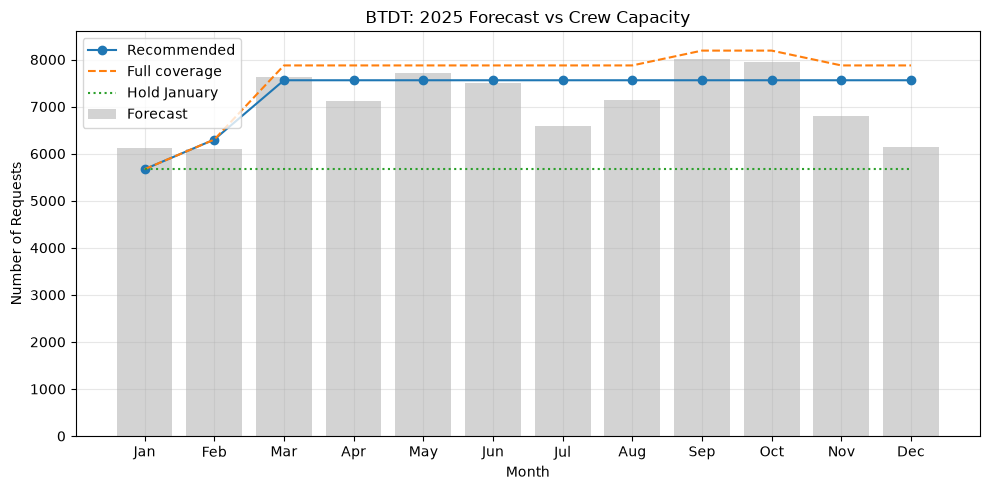

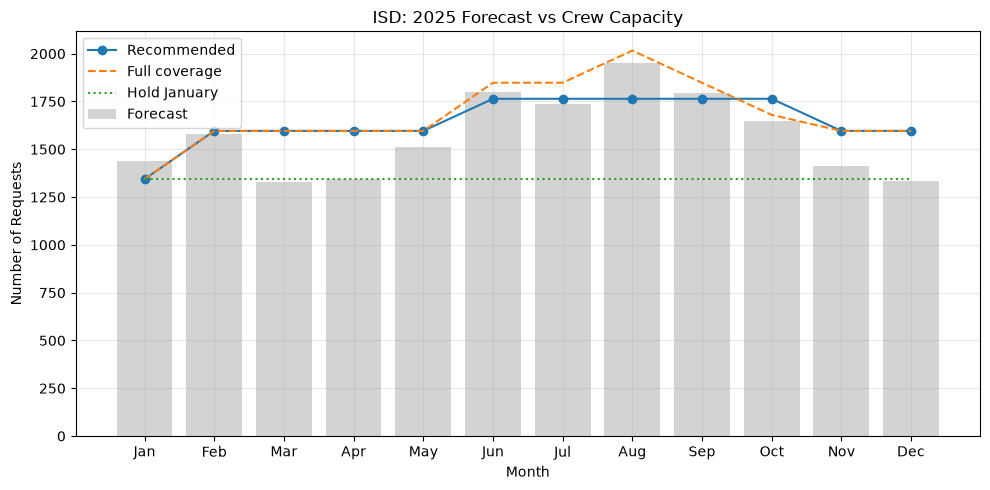

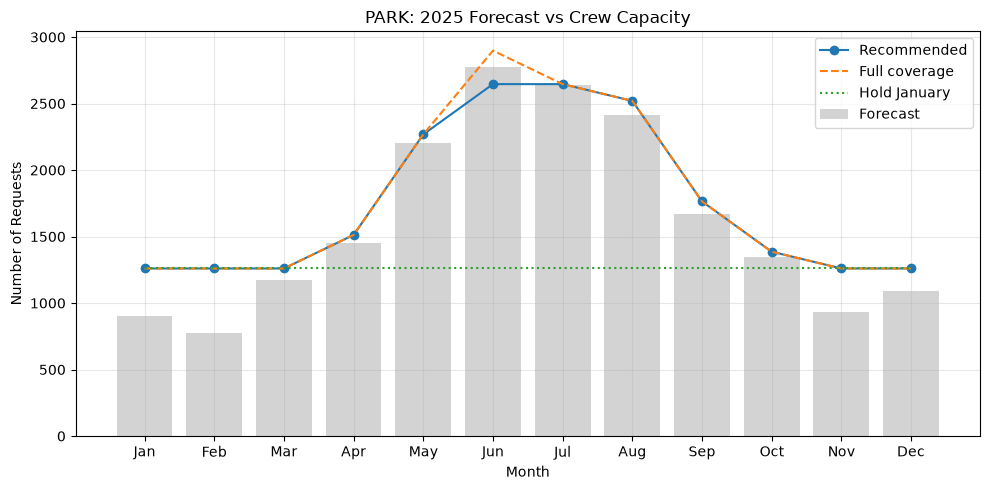

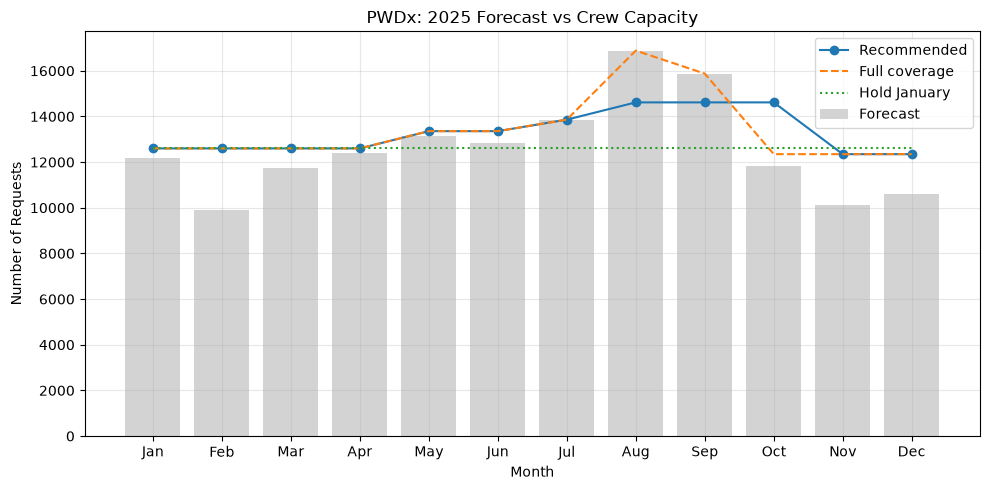

In [29]:
for dept in departments:
    capacity_per_crew = departments[dept]["monthly_capacity"]
    recommended = make_plan(dept, demand[dept], recommended_cap[dept])
    full = make_plan(dept, demand[dept])
    hold = hold_january_plan(dept, demand[dept])

    plt.figure(figsize=(10, 5))
    plt.bar(month_labels, demand[dept], color="lightgray", label="Forecast")
    plt.plot(month_labels, (recommended["permanent"] + recommended["seasonal"]) * capacity_per_crew, marker="o", label="Recommended")
    plt.plot(month_labels, (full["permanent"] + full["seasonal"]) * capacity_per_crew, linestyle="--", label="Full coverage")
    plt.plot(month_labels, hold["permanent"] * capacity_per_crew, linestyle=":", label="Hold January")

    plt.title(f"{dept}: 2025 Forecast vs Crew Capacity")
    plt.xlabel("Month")
    plt.ylabel("Number of Requests")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


### Export the staffing plan

This section saves the recommended crew plan and the plan comparison as CSV files in the `outputs` folder, the same folder the demand forecast uses.

In [30]:
# One row per department and month for the recommended plan
plan_rows = []
for dept in departments:
    plan = make_plan(dept, demand[dept], recommended_cap[dept])
    plan.insert(0, "department", dept)
    plan_rows.append(plan)
staffing_plan = pd.concat(plan_rows)

assert len(staffing_plan) == 48, "Expected 48 plan rows."

plan_file = OUTPUT_DIR / "staffing_plan_2025.csv"
comparison_file = OUTPUT_DIR / "staffing_plan_comparison_2025.csv"
staffing_plan.to_csv(plan_file, index=False)
comparison.to_csv(comparison_file, index=False)

print(f"CSV saved to: {plan_file.relative_to(DATA.parent)}")
print(f"CSV saved to: {comparison_file.relative_to(DATA.parent)}")


CSV saved to: outputs\staffing_plan_2025.csv
CSV saved to: outputs\staffing_plan_comparison_2025.csv


### Staffing conclusion

- Holding January crew levels all year is the most expensive plan ($19.31M), since the backlog builds up and about half of requests run late.
- The recommended plan hires ahead of demand, uses seasonal crews for the Parks summer peak, and releases crews in the fall once demand drops. It costs **$14.72M** and closes **96.3%** of requests in the same month.
- Full coverage gets to 99.7%, but it costs $0.64M more, mostly from crews hired for short peaks.

The next section tests how this plan holds up when demand is higher or lower than the forecast.

## Sensitivity and other considerations

**Author:** Larry Tsao

This section reuses the functions and the recommended plan from the staffing model.

### Five demand scenarios

This section keeps the recommended plan exactly as it is (same crews, hires, releases, and seasonal crews) and changes only the number of requests:

1. **Forecast:** the demand forecast, for comparison.
2. **Demand 20% higher:** every month 20% above the forecast.
3. **Demand 20% lower:** every month 20% below the forecast.
4. **February snowstorm:** Public Works gets 50% more requests in February.
5. **July heat wave:** Parks and Inspectional Services get 50% more requests in July.

The brief does not say how big a snowstorm or heat wave spike is. The 50% spikes are our team's assumption.

In [31]:
scenario_names = ["Forecast", "Demand 20% higher", "Demand 20% lower", "February snowstorm", "July heat wave"]


def scenario_demand(dept, scenario):
    # Returns the department's 12 monthly request counts under one scenario
    new_demand = []
    for m in range(12):
        requests_in_month = demand[dept][m]
        if scenario == "Demand 20% higher":
            requests_in_month = requests_in_month * 1.2
        elif scenario == "Demand 20% lower":
            requests_in_month = requests_in_month * 0.8
        elif scenario == "February snowstorm" and dept == "PWDx" and m == 1:
            requests_in_month = requests_in_month * 1.5
        elif scenario == "July heat wave" and dept in ["PARK", "ISD"] and m == 6:
            requests_in_month = requests_in_month * 1.5
        new_demand.append(round(requests_in_month))
    return new_demand


scenario_results = []
for scenario in scenario_names:
    for dept in departments:
        # Same recommended plan every time; only the requests change
        plan = make_plan(dept, demand[dept], recommended_cap[dept])
        plan["demand"] = scenario_demand(dept, scenario)
        result = simulate(dept, plan)
        result["scenario"] = scenario
        scenario_results.append(result)

scenario_results = pd.DataFrame(scenario_results)

# Totals across all four departments
scenario_totals = scenario_results.groupby("scenario", sort=False)[["total_cost", "overdue_cost", "requests", "closed_same_month", "backlog_in_december"]].sum()
scenario_totals["same_month_rate"] = scenario_totals["closed_same_month"] / scenario_totals["requests"]

scenario_summary = pd.DataFrame({
    "requests": scenario_totals["requests"],
    "total_cost ($M)": (scenario_totals["total_cost"] / 1_000_000).round(2),
    "overdue_cost ($M)": (scenario_totals["overdue_cost"] / 1_000_000).round(2),
    "same_month_rate": scenario_totals["same_month_rate"].round(3),
    "backlog_in_december": scenario_totals["backlog_in_december"],
})
print("Recommended plan under each scenario, all departments:")
display(scenario_summary)

print("Share of requests closed in the same month, by department:")
display(scenario_results.pivot(index="department", columns="scenario", values="same_month_rate")[scenario_names].round(3))


Recommended plan under each scenario, all departments:


,requests,total_cost ($M),overdue_cost ($M),same_month_rate,backlog_in_december
scenario,,,,,
Forecast,274347,14.72,0.20,0.963,0
Demand 20% higher,329217,24.98,10.46,0.314,41858
Demand 20% lower,219477,14.52,0.00,1.000,0
February snowstorm,279300,14.89,0.36,0.935,0
July heat wave,276535,14.95,0.43,0.922,1239


Share of requests closed in the same month, by department:


scenario,Forecast,Demand 20% higher,Demand 20% lower,February snowstorm,July heat wave
department,,,,,
BTDT,0.970,0.211,1.0,0.970,0.970
ISD,0.960,0.297,1.0,0.960,0.718
PARK,0.986,0.437,1.0,0.986,0.666
PWDx,0.957,0.359,1.0,0.906,0.957


#### Sensitivity analysis

The plan only stays above our 95% floor when demand is lower than the forecast.

- **Demand 20% higher:** total cost goes from $14.72M to $24.98M, and only 31.4% of requests get closed in the same month. 41,858 requests are still open in December. Overdue costs alone go up to $10.46M, because there aren't enough crews and the backlog keeps building.
- **Demand 20% lower:** every request gets closed in the same month, but the cost only drops to $14.52M, since the crews still get paid when there's less work.
- **February snowstorm:** Public Works drops from 95.7% to 90.6% closed in the same month (93.5% for all departments, under our 95% floor) and costs $0.16M more. It does catch up, so nothing is left open in December.
- **July heat wave:** Parks drops to 67% and ISD to 72% (92.2% overall), and it costs $0.23M more. 1,239 requests (702 Parks, 537 ISD) are still open in December, so those two departments don't catch up by the end of the year.

So a one-month spike doesn't cost much more, but service drops below our 95% floor, especially for Parks and ISD after a heat wave. If demand ends up a lot higher than the forecast for the whole year, the city would need more crews.

### Re-planning for 20% more or less demand

The scenario test above shows what happens if demand changes and the plan does not. This section shows the other side: if the city knew ahead of time that demand would be 20% higher or lower, what would the recommended plan look like? It reruns the recommended crew ceiling rule from the staffing model (the cheapest crew ceiling that still closes at least 95% of requests in the same month) on the changed demand.

In [32]:
def find_recommended_cap(dept, dept_demand):
    # Same rule as the recommended crew ceiling search: the cheapest ceiling that still closes at least 95% in the same month
    needed = get_crews_needed(dept, dept_demand)
    best_cap = max(needed)
    best_cost = None
    for cap in range(max(needed), min(needed) - 1, -1):
        result = simulate(dept, make_plan(dept, dept_demand, cap))
        if result["same_month_rate"] >= MIN_SAME_MONTH_RATE:
            if best_cost is None or result["total_cost"] < best_cost:
                best_cap = cap
                best_cost = result["total_cost"]
    if best_cost is None:
        print(f"{dept}: no ceiling reaches {MIN_SAME_MONTH_RATE:.0%}, so the highest need ({best_cap} crews) is used")
    return best_cap


replan_rows = []
for scenario in ["Demand 20% higher", "Demand 20% lower"]:
    for dept in departments:
        new_demand = scenario_demand(dept, scenario)

        # Plan kept the same, as in the scenario test
        kept_plan = make_plan(dept, demand[dept], recommended_cap[dept])
        kept_plan["demand"] = new_demand
        kept = simulate(dept, kept_plan)

        # Plan redone for the new demand
        new_cap = find_recommended_cap(dept, new_demand)
        redone = simulate(dept, make_plan(dept, new_demand, new_cap))

        replan_rows.append({
            "scenario": scenario,
            "department": dept,
            "ceiling_kept": recommended_cap[dept],
            "ceiling_redone": new_cap,
            "cost_kept ($M)": kept["total_cost"] / 1_000_000,
            "cost_redone ($M)": redone["total_cost"] / 1_000_000,
            "same_month_kept": kept["same_month_rate"],
            "same_month_redone": redone["same_month_rate"],
        })

replan = pd.DataFrame(replan_rows)
display(replan.round(3))

print("Totals ($ millions):")
display(replan.groupby("scenario")[["cost_kept ($M)", "cost_redone ($M)"]].sum().round(2))


,scenario,department,ceiling_kept,ceiling_redone,cost_kept ($M),cost_redone ($M),same_month_kept,same_month_redone
0,Demand 20% higher,BTDT,24,30,6.338,3.342,0.211,0.952
1,Demand 20% higher,ISD,21,26,3.570,3.555,0.297,0.955
2,Demand 20% higher,PARK,21,25,2.516,2.133,0.437,0.977
3,Demand 20% higher,PWDx,58,78,12.553,9.123,0.359,0.952
4,Demand 20% lower,BTDT,24,19,2.603,2.120,1.000,0.971
5,Demand 20% lower,ISD,21,17,2.870,2.351,1.000,0.979
6,Demand 20% lower,PARK,21,17,1.811,1.537,1.000,0.992
7,Demand 20% lower,PWDx,58,46,7.237,6.279,1.000,0.952


Totals ($ millions):


,cost_kept ($M),cost_redone ($M)
scenario,,
Demand 20% higher,24.98,18.15
Demand 20% lower,14.52,12.29


#### Re-planning analysis

If the city knew ahead of time that demand would be 20% higher, re-planning would cost $18.15M instead of $24.98M for keeping the same plan, and it would get back to about 95% closed in the same month. The crew ceilings would go up to 30 for BTDT, 26 for ISD, 25 for Parks, and 78 for Public Works.

If demand is 20% lower, re-planning saves $2.23M ($12.29M instead of $14.52M) by keeping fewer crews.

So I think the forecast should be checked during the year and the plan adjusted, since missing a 20% increase costs about $6.8M more than planning for it.

### Neighborhood equity in 2024

This section uses the real 2024 requests to compare neighborhoods within each department:

- **On-time rate:** the share of requests the city marked on time.
- **Median days to close (closed requests only):** half of the closed requests took longer than this. Requests still open have no close date, so they are not in the median, which makes a neighborhood with many open requests look faster than it is.
- **Still open:** the share of requests with no close date yet.

Neighborhoods with fewer than 100 requests in a department are left out (shown as blank), because a handful of requests can make a small neighborhood look very fast or very slow. Requests with no neighborhood are also left out. Neighborhoods also differ in the kinds of requests they send, so these numbers flag places to look at more closely rather than prove unequal service.

In [33]:
MIN_REQUESTS = 100

requests_2024 = requests[(requests["year"] == 2024) & requests["neighborhood"].notna()]

neighborhood_rows = []
for dept in departments:
    dept_requests = requests_2024[requests_2024["department"] == dept]
    for neighborhood in sorted(dept_requests["neighborhood"].unique()):
        area = dept_requests[dept_requests["neighborhood"] == neighborhood]
        neighborhood_rows.append({
            "department": dept,
            "neighborhood": neighborhood,
            "requests": len(area),
            "closed_requests": area["closed_dt"].notna().sum(),
            "on_time_rate": (area["on_time"] == "ONTIME").mean(),
            "median_days_to_close": area["days_to_close"].median(),
            "still_open": area["closed_dt"].isna().mean(),
        })

neighborhoods = pd.DataFrame(neighborhood_rows)
big_enough = neighborhoods[neighborhoods["requests"] >= MIN_REQUESTS]

print(f"On-time rate by neighborhood and department (2024, at least {MIN_REQUESTS} requests):")
display(big_enough.pivot(index="neighborhood", columns="department", values="on_time_rate").round(3))

# Five slowest neighborhoods in each department, by median days to close (sorted before rounding)
for dept in departments:
    dept_table = big_enough[big_enough["department"] == dept]
    slowest = dept_table.sort_values("median_days_to_close", ascending=False).head(5)
    department_median = requests_2024[requests_2024["department"] == dept]["days_to_close"].median()
    print(f"{dept}: five slowest neighborhoods (department median {department_median:.1f} days, closed requests only)")
    display(slowest[["neighborhood", "requests", "closed_requests", "on_time_rate", "median_days_to_close", "still_open"]].round(3))


On-time rate by neighborhood and department (2024, at least 100 requests):


department,BTDT,ISD,PARK,PWDx
neighborhood,,,,
Allston,0.562,0.845,0.947,0.917
Allston / Brighton,0.550,0.777,0.952,0.895
Back Bay,0.511,0.762,0.911,0.873
Beacon Hill,0.511,0.755,0.934,0.916
Boston,0.579,0.771,0.893,0.860
Brighton,0.567,0.769,0.932,0.851
Charlestown,0.426,0.712,0.911,0.804
Dorchester,0.486,0.710,0.934,0.920
Downtown / Financial District,0.504,0.697,0.915,0.878


BTDT: five slowest neighborhoods (department median 1.0 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
13,Hyde Park,2027,1660,0.394,4.275,0.181
22,West Roxbury,1678,1369,0.365,4.220,0.184
12,Greater Mattapan,1987,1663,0.443,3.569,0.163
17,Roslindale,2736,2210,0.425,3.021,0.192
14,Jamaica Plain,5566,4342,0.392,2.971,0.220


ISD: five slowest neighborhoods (department median 2.8 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
35,Greater Mattapan,967,792,0.624,4.559,0.181
29,Charlestown,500,457,0.712,4.044,0.086
34,Fenway / Kenmore / Audubon Circle / Longwood,416,377,0.702,4.000,0.094
41,Roxbury,2134,1903,0.713,3.798,0.108
33,East Boston,1153,1053,0.645,3.495,0.087


PARK: five slowest neighborhoods (department median 2.1 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
59,Hyde Park,706,697,0.956,12.412,0.013
49,Beacon Hill,396,393,0.934,6.842,0.008
66,South Boston / South Boston Waterfront,879,879,0.968,6.814,0.000
68,West Roxbury,1236,1223,0.964,6.759,0.011
47,Allston / Brighton,1004,1001,0.952,4.878,0.003


PWDx: five slowest neighborhoods (department median 0.2 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
82,Hyde Park,7571,5926,0.887,0.616,0.217
91,West Roxbury,5931,4242,0.873,0.599,0.285
86,Roslindale,5819,4492,0.893,0.545,0.228
83,Jamaica Plain,9009,7669,0.876,0.515,0.149
75,Charlestown,3909,3234,0.804,0.451,0.173


#### Neighborhood analysis

- **BTDT:** the five slowest are Hyde Park, West Roxbury, Greater Mattapan, Roslindale, and Jamaica Plain, with medians of about 3 to 4.3 days for closed requests compared to 1 day for the whole department. They also have some of the lowest on-time rates (37% to 44%).
- **ISD:** Greater Mattapan is the slowest at 4.6 days (the department median is 2.8), and 18% of its requests are still open.
- **PARK:** Hyde Park takes 12.4 days, about six times the department median of 2.1 days, but the city still marks 96% of them on time, probably because a lot of Parks requests have long target dates.
- **PWDx:** the medians are all under a day, but they only count closed requests. The bigger difference is the requests still open: 28.5% in West Roxbury and 21.7% in Hyde Park.

Hyde Park and West Roxbury are in the slowest five for three departments (BTDT, Parks, and Public Works), so I think those two neighborhoods should be looked at first. These are flags to look into, not proof of unequal service, since neighborhoods send different kinds of requests. Also, the city's neighborhood names overlap (for example "Allston", "Brighton", and "Allston / Brighton" are all used), so some areas are split across more than one name.

### City employees vs residents in 2024

The `source` column says how each request came in. Two sources come from city staff: **Employee Generated** and the **City Worker App**. The other three come from residents: the **Citizens Connect App**, a **Constituent Call**, and **Self Service** online.

This section compares the five sources on volume, on-time rate, days to close, and the most common request types. Because the city marks every request with no target date as on time (see the simulation check against 2024), it also shows how many requests have no target date and the on-time rate for requests that do have one. Sources send different kinds of requests to different departments, so this describes the differences rather than proving one group gets faster service.

In [34]:
city_staff_sources = ["Employee Generated", "City Worker App"]

requests_2024_all = requests[requests["year"] == 2024]

source_rows = []
for source in requests_2024_all["source"].value_counts().index:
    from_source = requests_2024_all[requests_2024_all["source"] == source]
    if source in city_staff_sources:
        reported_by = "City staff"
    else:
        reported_by = "Resident"
    source_rows.append({
        "source": source,
        "reported_by": reported_by,
        "requests": len(from_source),
        "share_of_requests": round(len(from_source) / len(requests_2024_all), 3),
        "on_time_rate": round((from_source["on_time"] == "ONTIME").mean(), 3),
        "no_target_date": round(from_source["sla_target_dt"].isna().mean(), 3),
        "on_time_with_target": round((from_source[from_source["sla_target_dt"].notna()]["on_time"] == "ONTIME").mean(), 3),
        "median_days_to_close": round(from_source["days_to_close"].median(), 1),
        "still_open": round(from_source["closed_dt"].isna().mean(), 3),
    })

sources = pd.DataFrame(source_rows)
display(sources)

# City staff vs residents, with their sources added together
resident_sources = ["Citizens Connect App", "Constituent Call", "Self Service"]
group_rows = []
for reported_by, group_sources in [("City staff", city_staff_sources), ("Resident", resident_sources)]:
    group = requests_2024_all[requests_2024_all["source"].isin(group_sources)]
    group_rows.append({
        "reported_by": reported_by,
        "requests": len(group),
        "share_of_requests": round(len(group) / len(requests_2024_all), 3),
        "on_time_rate": round((group["on_time"] == "ONTIME").mean(), 3),
        "no_target_date": round(group["sla_target_dt"].isna().mean(), 3),
        "on_time_with_target": round((group[group["sla_target_dt"].notna()]["on_time"] == "ONTIME").mean(), 3),
        "median_days_to_close": round(group["days_to_close"].median(), 2),
        "still_open": round(group["closed_dt"].isna().mean(), 3),
    })
staff_vs_residents = pd.DataFrame(group_rows)
print("City staff vs residents (2024):")
display(staff_vs_residents)

# On-time rate for requests with a target date, by department and who reported them
with_target = requests_2024_all[requests_2024_all["sla_target_dt"].notna()]
target_rows = []
for dept in departments:
    dept_with_target = with_target[with_target["department"] == dept]
    staff = dept_with_target[dept_with_target["source"].isin(city_staff_sources)]
    residents = dept_with_target[dept_with_target["source"].isin(resident_sources)]
    target_rows.append({
        "department": dept,
        "city_staff_on_time": round((staff["on_time"] == "ONTIME").mean(), 3),
        "resident_on_time": round((residents["on_time"] == "ONTIME").mean(), 3),
    })
print("On-time rate for requests with a target date, by department (2024):")
display(pd.DataFrame(target_rows))

# Each row adds up to 1: the share of that department's requests from each source
print("Share of each department's requests by source (2024):")
display(pd.crosstab(requests_2024_all["department"], requests_2024_all["source"], normalize="index").round(3))

print("Most common request types for each source (2024):")
for source in sources["source"]:
    top_types = requests_2024_all[requests_2024_all["source"] == source]["type"].value_counts().head(3)
    print(source)
    for request_type in top_types.index:
        print(f"   {request_type}: {top_types[request_type]:,}")


,source,reported_by,requests,share_of_requests,on_time_rate,no_target_date,on_time_with_target,median_days_to_close,still_open
0,Employee Generated,City staff,116828,0.423,0.724,0.043,0.712,0.5,0.134
1,Citizens Connect App,Resident,68476,0.248,0.708,0.008,0.706,0.5,0.120
2,Constituent Call,Resident,49551,0.179,0.857,0.370,0.773,1.9,0.211
3,City Worker App,City staff,30337,0.110,0.886,0.003,0.886,0.1,0.008
4,Self Service,Resident,11225,0.041,0.941,0.660,0.827,0.7,0.657


City staff vs residents (2024):


,reported_by,requests,share_of_requests,on_time_rate,no_target_date,on_time_with_target,median_days_to_close,still_open
0,City staff,147165,0.532,0.758,0.035,0.749,0.35,0.108
1,Resident,129252,0.468,0.785,0.203,0.730,0.75,0.201


On-time rate for requests with a target date, by department (2024):


,department,city_staff_on_time,resident_on_time
0,BTDT,0.495,0.480
1,ISD,0.747,0.707
2,PARK,0.948,0.902
3,PWDx,0.890,0.852


Share of each department's requests by source (2024):


source,Citizens Connect App,City Worker App,Constituent Call,Employee Generated,Self Service
department,,,,,
BTDT,0.329,0.003,0.049,0.613,0.006
ISD,0.133,0.013,0.427,0.390,0.038
PARK,0.274,0.238,0.111,0.365,0.012
PWDx,0.216,0.161,0.225,0.335,0.062


Most common request types for each source (2024):
Employee Generated
   Parking Enforcement: 41,618
   Improper Storage of Trash (Barrels): 11,466
   Requests for Street Cleaning: 9,488
Citizens Connect App
   Parking Enforcement: 20,406
   Requests for Street Cleaning: 8,635
   Improper Storage of Trash (Barrels): 8,466
Constituent Call
   Mattress Pickup: 8,448
   Schedule a Bulk Item Pickup: 8,347
   Missed Trash/Recycling/Yard Waste/Bulk Item: 5,222
City Worker App
   CE Collection: 18,009
   Tree Maintenance Requests: 3,297
   Recycling Cart Return: 2,874
Self Service
   Schedule a Bulk Item Pickup SS: 7,409
   Sticker Request: 1,076
   Missed Trash/Recycling/Yard Waste/Bulk Item: 1,032


#### Employee vs resident analysis

City staff reported 53% of the requests in 2024, mostly through Employee Generated (42%), and a lot of those are Parking Enforcement.

- At first residents look a bit more on time (79% vs 76%), but that's because 20% of resident requests have no target date and the city counts those as on time. Looking only at requests with a target date, city staff requests are on time 75% of the time vs 73% for residents, and city staff are slightly ahead in every department.
- Among closed requests, city staff requests also close faster (a median of 0.35 days vs 0.75).
- **Self Service** has the highest on-time rate (94%), but 66% of those requests have no target date and 66% are still open. Its most common type is scheduled bulk item pickups (7,409 of 11,225). Counting only requests with a target date, it drops to 83%.
- **City Worker App** requests are the fastest (0.1 days) and almost none are still open. My guess is that workers report problems they can fix on the spot, but the data doesn't show that.
- BTDT gets 61% of its requests from Employee Generated, while ISD gets 43% from phone calls.

So the overall on-time rate can make some sources look better than they are. Since each source sends different kinds of requests, I think this shows where to look more closely, not that one group gets faster service.

### Export the sensitivity tables

This section saves the scenario results, the re-planning comparison, the neighborhood table, and the source table in the `outputs` folder.

In [35]:
scenario_file = OUTPUT_DIR / "sensitivity_scenarios_2025.csv"
replan_file = OUTPUT_DIR / "sensitivity_replan_2025.csv"
neighborhood_file = OUTPUT_DIR / "neighborhood_equity_2024.csv"
source_file = OUTPUT_DIR / "request_sources_2024.csv"

scenario_results.to_csv(scenario_file, index=False)
replan.to_csv(replan_file, index=False)
neighborhoods.to_csv(neighborhood_file, index=False)
sources.to_csv(source_file, index=False)

for saved_file in [scenario_file, replan_file, neighborhood_file, source_file]:
    print(f"CSV saved to: {saved_file.relative_to(DATA.parent)}")


CSV saved to: outputs\sensitivity_scenarios_2025.csv
CSV saved to: outputs\sensitivity_replan_2025.csv
CSV saved to: outputs\neighborhood_equity_2024.csv
CSV saved to: outputs\request_sources_2024.csv


### Sensitivity conclusion

- A one-month spike like a snowstorm or heat wave only costs about $0.2M extra, but it pushes same-month closures under our 95% floor (93.5% and 92.2%), and the heat wave leaves 1,239 requests open in December.
- If demand is 20% higher all year, only 31% of requests get closed in the same month and the cost goes up to about $25M. Re-planning for that increase would cost $18.15M instead, so the forecast should be checked during the year and the plan updated if demand runs high.
- Hyde Park and West Roxbury are among the slowest neighborhoods in three departments.
- The city counts requests with no target date as on time, which makes residents look more on time than city staff. Counting only requests with a target date, city staff come out slightly ahead.

## Intake assistant and accuracy

The data has no free-text descriptions from residents, so the assistant matches a resident's message against the list of request types. This section embeds the request types, adds resident phrasings written by an LLM, and measures search accuracy on synthetic test messages. The demo at the end of the notebook runs the full assistant.

### Embedding function

- Model: OpenAI `text-embedding-3-small`, 1,536 dimensions, called through the same OpenRouter key as the LLM.
- `db/request_types.py` creates it from LanceDB's built-in `openai` embedding function.
- The intake agent imports the same module, so LanceDB embeds the source column on write and the query text on search with the same model.

### Request types

- One row per type. The same type is sometimes filed under several departments (Request for Pothole Repair appears under Transportation, Parks and Inspectional Services with a few dozen rows, against 16,927 in Public Works). 
- Each type is kept under the department that handles most of its requests. `queue` is the most common queue for that row, and `n_requests` is its volume over 2023 and 2024.
- The embedded text is the type, reason and subject plus the department name, then the resident phrasings from the next section. The queue is a routing code, so it stays out of the text.

In [36]:
types = (
    requests.groupby(["department", "type", "reason", "subject"], as_index=False)
    .agg(queue=("queue", mode), n_requests=("case_enquiry_id", "size"))
    .sort_values("n_requests", ascending=False)
    .drop_duplicates("type")
    .reset_index(drop=True)
)
types["department_name"] = types.department.map(DEPARTMENTS)
types["text_plain"] = types.type + ". " + types.reason + ". " + types.subject + ". " + types.department_name
print(f"{len(types)} request types")
types.head(3)[["department", "type", "queue", "n_requests"]]


163 request types


,department,type,queue,n_requests
0,BTDT,Parking Enforcement,BTDT Parking Enforcement,119597
1,PWDx,Requests for Street Cleaning,PWDx District 1C: Downtown,39681
2,PWDx,Improper Storage of Trash (Barrels),PWDx Code Enforcement,39541


Median days to close and on-time rate are per type, over 2024 requests only. Open requests have no close date and drop out of the median.

In [37]:
stats_2024 = (
    requests[requests.open_dt.dt.year == 2024]
    .groupby("type")
    .agg(median_days_to_close=("days_to_close", "median"), on_time_rate_2024=("is_on_time", "mean"))
)
types = types.merge(stats_2024, on="type", how="left")


### Resident phrasing

- Type names are agency labels ("CE Collection", "BWSC Pothole") but residents do not write like that. 
- An LLM writes a few everyday phrasings per type, grounded in the type's most common case titles, and those get embedded with the type text.
- Calls go through `core.llm` with Pydantic models from `core.models`, in batches of 20 types. 
- Results are cached in the `type_aliases` table, so only types without aliases are sent.

In [38]:
ALIAS_PROMPT = """You help a Boston 311 intake assistant match what residents write to city request types.
For each numbered request type, write 6 short phrases a resident might use to report that problem in everyday words.
Use plain language, no department jargon, and do not repeat the type name. The example titles show what the type covers."""

types["resident_share"] = types.type.map(1 - requests.groupby("type").is_employee.mean())
types["examples"] = types.type.map(requests.groupby("type").case_title.agg(lambda s: "; ".join(s.value_counts().index[:3])))


def table_names() -> list[str]:
    return db.list_tables().tables


def generate_aliases(todo: pd.DataFrame) -> None:
    for start in range(0, len(todo), 20):
        batch = todo.iloc[start:start + 20]
        prompt = "\n".join(f"{i}. {r['type']} | {r['reason']} | {r['subject']} | {r['department_name']} | example titles: {r['examples']}" for i, r in batch.iterrows())
        found = {a.type_id: a.aliases for a in parse(AliasBatch, ALIAS_PROMPT, prompt).items if a.type_id in batch.index}
        rows = [{"type": batch.type[i], "aliases": aliases} for i, aliases in found.items()]
        if "type_aliases" in table_names():
            db.open_table("type_aliases").add(rows)
        else:
            db.create_table("type_aliases", rows)


done = set(db.open_table("type_aliases").to_pandas().type) if "type_aliases" in table_names() else set()
generate_aliases(types[~types.type.isin(done)])
aliases = db.open_table("type_aliases").to_pandas().set_index("type").aliases
extra = types.type.map(lambda t: "; ".join(aliases.get(t, [])))
types["text"] = types.text_plain + (". Also reported as: " + extra).where(extra != "", "")
print(f"{MODEL}: {types.type.isin(aliases.index).sum()} of {len(types)} types have aliases")
types.sample(3, random_state=0).text.tolist()


openai/gpt-4o-mini: 163 of 163 types have aliases


["Undefined Noise Disturbance. Generic Noise Disturbance. Mayor's 24 Hour Hotline. Inspectional Services. Also reported as: I can't sleep because of loud noises.; There's a party that won't stop making noise.; I hear strange sounds at night.; My neighbor is making too much noise.; There's a construction site causing disturbances.; Can someone check on the noise outside?",
 "Scale Not Visible. Weights and Measures. Inspectional Services. Inspectional Services. Also reported as: Can't see the scale at the store; The weight scale isn't working; The price is unclear because the scale is hidden; Where's the scale? I need to weigh this; The scale isn't visible for customers; Can the scale be fixed or moved?",
 "Food Alert - Unconfirmed. Health. Inspectional Services. Inspectional Services. Also reported as: There's an unsanitary food place nearby.; Can someone check this restaurant for hygiene?; I think there’s a food issue at the market.; I've seen bad conditions at this food vendor.; It's 

### Synthetic test messages

- 40 types are sampled, weighted by the square root of their volume. 
- Only types that residents actually file (at least 20% non-employee requests, at least 100 requests) are eligible. 
- The LLM writes one message per type from the type name only, never from the aliases or titles. 
- Messages are cached in the `intake_eval` table.

In [39]:
EVAL_PROMPT = """You write test messages for a Boston 311 intake assistant. For each numbered request type, write one message a real resident might send to report that problem.
Vary the style: some short and vague, some with a street name or landmark, some with typos or frustration. Never copy the wording of the request type or reason."""

if "intake_eval" not in table_names():
    pool = types[(types.resident_share >= 0.2) & (types.n_requests >= 100)]
    weights = pool.n_requests ** 0.5
    sample = pool.loc[np.random.default_rng(0).choice(pool.index, 40, replace=False, p=weights / weights.sum())]
    rows = []
    for start in range(0, len(sample), 20):
        batch = sample.iloc[start:start + 20]
        prompt = "\n".join(f"{i}. {r['type']} | {r['reason']} | {r['department_name']}" for i, r in batch.iterrows())
        for m in parse(EvalBatch, EVAL_PROMPT, prompt).items:
            if m.type_id in batch.index:
                row = batch.loc[m.type_id]
                rows.append({"message": m.message, "type": row["type"], "department": row.department, "queue": row.queue})
    db.create_table("intake_eval", rows)

eval_set = db.open_table("intake_eval").to_pandas()
print(f"{len(eval_set)} test messages")
eval_set.sample(6, random_state=0)[["message", "type"]]


40 test messages


,message,type
22,My sidewalk is totally ice-covered and impossi...,Unshoveled Sidewalk
20,Need someone to check the plumbing in our apar...,Plumbing
25,"I keep seeing rats near the trash at my place,...",Rodent Activity
4,There's someone selling food on the corner of ...,Illegal Vending
10,"The potholes on my street are terrible, need s...",Roadway Repair
15,People are leaving their trash barrels out all...,Improper Storage of Trash (Barrels)


In [40]:
TYPE_COLUMNS = ["text", "department", "department_name", "queue", "type", "reason", "subject", "n_requests", "median_days_to_close", "on_time_rate_2024"]


class RequestType(LanceModel):
    text: str = embedder.SourceField()
    vector: Vector(embedder.ndims()) = embedder.VectorField()
    department: str
    department_name: str
    queue: str
    type: str
    reason: str
    subject: str
    n_requests: int
    median_days_to_close: float | None = None
    on_time_rate_2024: float | None = None

tbl = db.create_table("request_types", schema=RequestType, mode="overwrite", data=types[TYPE_COLUMNS])
tbl.create_index("text", config=FTS(), replace=True)
tbl.count_rows()


163

### Accuracy on synthetic messages

For each message, search the index and see where the right type lands. The same run on an index built without aliases shows what the aliases add.

The messages come from the same LLM that wrote the aliases, so the scores are optimistic. Hand-written messages are the honest test.

In [41]:
def evaluate(table, k: int = 5) -> pd.Series:
    ranks, dept_hits = [], []
    for message, truth, dept in zip(eval_set.message, eval_set.type, eval_set.department):
        hits = table.search(message, query_type="hybrid").limit(k).to_pandas()
        found = hits.type.tolist()
        ranks.append(found.index(truth) + 1 if truth in found else None)
        dept_hits.append(hits.department.iloc[0] == dept)
    r = pd.Series(ranks, dtype="float")
    return pd.Series({"type_top1": (r == 1).mean(), "type_top3": (r <= 3).mean(), "type_top5": r.notna().mean(), "department_top1": sum(dept_hits) / len(dept_hits)})


plain = db.create_table("request_types_plain", schema=RequestType, mode="overwrite", data=types[TYPE_COLUMNS].assign(text=types.text_plain))
plain.create_index("text", config=FTS(), replace=True)
comparison = pd.DataFrame({"without aliases": evaluate(plain), "with aliases": evaluate(tbl)}).round(3)
db.drop_table("request_types_plain")
comparison


,without aliases,with aliases
type_top1,0.425,0.625
type_top3,0.725,0.850
type_top5,0.850,0.900
department_top1,0.850,0.875


### Search

`tbl.search(text)` embeds the query with the same function and runs vector search. `query_type="hybrid"` adds full text search on the same column. Sample messages in the spirit of the hackathon brief:

In [42]:
MESSAGES = [
    "there's a big hole on Centre St near the T stop",
    "someone parked across my driveway again",
    "the streetlight on my corner has been out for a week",
    "rats behind the restaurant on Washington St",
    "overflowing trash barrels outside the apartment next door",
    "dead tree limb hanging over the playground",
    "landlord won't fix the heat",
]
for msg in MESSAGES:
    hits = tbl.search(msg, query_type="hybrid").limit(3).to_pandas()
    print(msg)
    for r in hits.itertuples():
        print(f"    {r.department:5} {r.queue:40} {r.type}")


there's a big hole on Centre St near the T stop
    PWDx  PWDx Contractor Complaints               BWSC Pothole
    PWDx  PWDx Highway Construction                Sidewalk Cover / Manhole
    PWDx  PWDx District 06: West Roxbury and Roslindale City/State Snow Issues
someone parked across my driveway again
    BTDT  BTDT Parking Enforcement                 Parking Enforcement
    BTDT  BTDT Parking Lot PrivateParkingLotComplaints Private Parking Lot Complaints
    PWDx  PWDx Code Enforcement                    Parking on Front/Back Yards (Illegal Parking)
the streetlight on my corner has been out for a week
    PWDx  PWDx Highway Construction General        StreetLight Pole WO
    PWDx  PWDx Street Light Outages                Street Light Outages
    PWDx  PWDx Street Light Knockdown Replacement  Knockdown Replacement
rats behind the restaurant on Washington St
    PWDx  PWDx Contractor Complaints               BWSC Pothole
    ISD   ISD Environmental Services (INTERNAL)    Rat Bite
  

### Check

The database folder should now hold all four tables, and each request type should have its SLA metrics.

In [43]:
print(db.list_tables().tables)
db.open_table("request_types").to_pandas()[["type", "median_days_to_close", "on_time_rate_2024"]].head()


['intake_eval', 'request_types', 'requests', 'type_aliases']


,type,median_days_to_close,on_time_rate_2024
0,Parking Enforcement,0.700023,0.482113
1,Requests for Street Cleaning,0.093271,0.965425
2,Improper Storage of Trash (Barrels),0.120141,0.997394
3,Mattress Pickup,2.953076,1.000000
4,CE Collection,0.068883,0.993393


## Intake assistant demo

A resident types a complaint in plain English, for example "there's a big hole on Centre St near the T stop". The agent searches the request types using everything the resident has said so far, then the LLM picks the type, department and queue from those results. When it is confident, the reply also gives the typical days to close for that type and its 2024 on-time rate. When the message is vague, it asks one clarifying question instead.

The `%%blocks` cell runs the app inside the notebook. Running it again reloads the agent and UI code without restarting the kernel.

In [45]:
%load_ext gradio


In [ ]:
%%blocks
import importlib

import agents.intake.agent as agent
import ui.gradio_app as app

for module in (agent, app):
    importlib.reload(module)
demo = app.demo


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


d:\Projects\School\Northeastern\DADS_5250_AI_in_Practice\hackathon\dads5250-311-intake-assistant\.venv\Lib\site-packages\gradio\routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
ERROR:root:Bad request: ['']
Traceback (most recent call last):
  File "d:\Projects\School\Northeastern\DADS_5250_AI_in_Practice\hackathon\dads5250-311-intake-assistant\.venv\Lib\site-packages\lancedb\embeddings\openai.py", line 109, in generate_embeddings
    rs = self._openai_client.embeddings.create(**kwargs)
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Projects\School\Northeastern\DADS_5250_AI_in_Practice\hackathon\dads5250-311-intake-assistant\.venv\Lib\site-packages\openai\resources\embeddings.py", line 113, in create
    return self._post(
           ^^^^^^^^^^^
  File "d:\Projects\School\Northeastern\DADS_5250_AI_in_Practice\hackathon\da

### Write User Request to Database

In [44]:
# Create the table
from datetime import datetime
from lancedb.pydantic import LanceModel, Vector
from db.request_types import embedder, DATA
import lancedb

class FiledRequest(LanceModel):
    resident_message: str = embedder.SourceField()
    vector: Vector(embedder.ndims()) = embedder.VectorField()
    type: str
    department: str
    queue: str
    confidence: float
    filed_at: str

db = lancedb.connect(DATA / "request_types.lance")
filed = db.create_table("filed_requests", schema=FiledRequest, exist_ok=True)